# Entregable II: Entrenamiento, Evaluación de Modelos y Reducción de Dimensión
## Cybersecurity Threat Severity and Impact Classification

**Proyecto de Aula — Modelos y Simulación de Sistemas II**  
*Departamento de Ingeniería de Sistemas — Universidad de Antioquia*  
**Autores:** Luis Carlos Vanegas Zapata, Alejandra Cano Espinosa, Robinson Dario Henao Botero  

---

## Descripción General del Entregable II

Este cuaderno desarrolla íntegramente la segunda fase del proyecto de clasificación de amenazas de ciberseguridad, con continuidad estricta respecto al Entregable I. El objetivo central es predecir la severidad (`Severity`: Low, Medium, High) de incidentes cibernéticos **exclusivamente a partir de atributos observables al momento del reporte** ($t=0$), evitando cualquier forma de fuga de datos (*data leakage*).

El cuaderno cubre:

1. **Sección 1 — Entrenamiento y Evaluación de Modelos (30%)**:
   - Diseño experimental: validación cruzada estratificada ($K=5$) + partición *holdout* 80/20.
   - Sintonización de hiperparámetros para 5 familias de aprendizaje supervisado.
   - Métricas de desempeño con intervalos de confianza al 95%.
   - Visualización del efecto de hiperparámetros y matrices de confusión.

2. **Sección 2 — Reducción de Dimensión (20%)**:
   - Análisis discriminativo individual: ANOVA $F$-statistic e Información Mutua.
   - Extracción lineal con PCA: criterio de varianza acumulada ≥ 90%.
   - Extracción no lineal con UMAP: proyección a 5 componentes latentes.
   - Reevaluación de los dos mejores modelos en los espacios reducidos.
   - Discusión integral y conclusiones de ingeniería de datos.

## 1. Configuración del Entorno y Descarga del Dataset

Se importan todas las bibliotecas necesarias y se descarga el conjunto de datos directamente desde Kaggle usando `kagglehub`. Esta descarga garantiza que los resultados sean reproducibles usando la versión publicada del dataset.

**Dataset:** *Global Cybersecurity Threats 2015–2024* (Soundankar, 2024)  
**Dimensiones originales:** 3,000 registros × 10 columnas  
**Variables:** 6 categóricas + 4 numéricas, sin valores faltantes.

> **Nota metodológica:** Se establece la semilla `random_state=42` en todos los componentes estocásticos para garantizar la reproducibilidad exacta de los experimentos.

In [1]:
import os
import glob
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

# -----------------------------------------------------------------
# Descarga del dataset mediante kagglehub (fuente principal en línea)
# -----------------------------------------------------------------
import kagglehub

path = kagglehub.dataset_download('atharvasoundankar/global-cybersecurity-threats-2015-2024')
print('Path to dataset files:', path)

csv_files = glob.glob(os.path.join(path, '*.csv'))
df = pd.read_csv(csv_files[0])
df.columns = [c.strip() for c in df.columns]   # limpiar espacios en nombres

print(f'\nDimensiones del dataset: {df.shape[0]} registros × {df.shape[1]} columnas')
print(f'Columnas: {list(df.columns)}')
df.head()

100%|██████████| 47.0k/47.0k [00:00<00:00, 14.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/atharvasoundankar/global-cybersecurity-threats-2015-2024/versions/1

Dimensiones del dataset: 3000 registros × 10 columnas
Columnas: ['Country', 'Year', 'Attack Type', 'Target Industry', 'Financial Loss (in Million $)', 'Number of Affected Users', 'Attack Source', 'Security Vulnerability Type', 'Defense Mechanism Used', 'Incident Resolution Time (in Hours)']


,Country,Year,Attack Type,Target Industry,Financial Loss (in Million $),Number of Affected Users,Attack Source,Security Vulnerability Type,Defense Mechanism Used,Incident Resolution Time (in Hours)
0,China,2019,Phishing,Education,80.53,773169,Hacker Group,Unpatched Software,VPN,63
1,China,2019,Ransomware,Retail,62.19,295961,Hacker Group,Unpatched Software,Firewall,71
2,India,2017,Man-in-the-Middle,IT,38.65,605895,Hacker Group,Weak Passwords,VPN,20
3,UK,2024,Ransomware,Telecommunications,41.44,659320,Nation-state,Social Engineering,AI-based Detection,7
4,Germany,2018,Man-in-the-Middle,IT,74.41,810682,Insider,Social Engineering,VPN,68


### 1.1 Exploración Inicial del Dataset

Se verifica la ausencia de valores faltantes y se revisan las estadísticas descriptivas de las variables numéricas. Esta exploración confirma la consistencia y completitud de los datos antes del preprocesamiento.

In [2]:
# Verificación de valores nulos
print('=== Valores Nulos por Columna ===')
print(df.isnull().sum())
print('\n→ El dataset NO contiene valores faltantes.')

# Tipos de datos
print('\n=== Tipos de Datos ===')
print(df.dtypes)

# Estadísticas descriptivas
print('\n=== Estadísticas Descriptivas (Variables Numéricas) ===')
df[['Year', 'Financial Loss (in Million $)',
    'Number of Affected Users', 'Incident Resolution Time (in Hours)']].describe()

=== Valores Nulos por Columna ===
Country                                0
Year                                   0
Attack Type                            0
Target Industry                        0
Financial Loss (in Million $)          0
Number of Affected Users               0
Attack Source                          0
Security Vulnerability Type            0
Defense Mechanism Used                 0
Incident Resolution Time (in Hours)    0
dtype: int64

→ El dataset NO contiene valores faltantes.

=== Tipos de Datos ===
Country                                 object
Year                                     int64
Attack Type                             object
Target Industry                         object
Financial Loss (in Million $)          float64
Number of Affected Users                 int64
Attack Source                           object
Security Vulnerability Type             object
Defense Mechanism Used                  object
Incident Resolution Time (in Hours)      int64
dtyp

,Year,Financial Loss (in Million $),Number of Affected Users,Incident Resolution Time (in Hours)
count,3000.000000,3000.000000,3000.000000,3000.000000
mean,2019.570333,50.492970,504684.136333,36.476000
std,2.857932,28.791415,289944.084972,20.570768
min,2015.000000,0.500000,424.000000,1.000000
25%,2017.000000,25.757500,255805.250000,19.000000
50%,2020.000000,50.795000,504513.000000,37.000000
75%,2022.000000,75.630000,758088.500000,55.000000
max,2024.000000,99.990000,999635.000000,72.000000


In [3]:
# Distribución de valores únicos en variables categóricas
cat_vars = ['Country', 'Attack Type', 'Target Industry',
            'Attack Source', 'Security Vulnerability Type', 'Defense Mechanism Used']

print('=== Valores Únicos por Variable Categórica ===')
for col in cat_vars:
    vals = df[col].unique()
    print(f'  {col}: {len(vals)} categorías -> {list(vals)}')

=== Valores Únicos por Variable Categórica ===
  Country: 10 categorías -> ['China', 'India', 'UK', 'Germany', 'France', 'Australia', 'Russia', 'Brazil', 'Japan', 'USA']
  Attack Type: 6 categorías -> ['Phishing', 'Ransomware', 'Man-in-the-Middle', 'DDoS', 'SQL Injection', 'Malware']
  Target Industry: 7 categorías -> ['Education', 'Retail', 'IT', 'Telecommunications', 'Government', 'Banking', 'Healthcare']
  Attack Source: 4 categorías -> ['Hacker Group', 'Nation-state', 'Insider', 'Unknown']
  Security Vulnerability Type: 4 categorías -> ['Unpatched Software', 'Weak Passwords', 'Social Engineering', 'Zero-day']
  Defense Mechanism Used: 5 categorías -> ['VPN', 'Firewall', 'AI-based Detection', 'Antivirus', 'Encryption']


## 2. Continuidad del Entregable I: Construcción de la Variable Objetivo y Preprocesamiento

Se sigue exactamente la metodología formalizada en el Entregable I para garantizar la continuidad metodológica del proyecto:

### 2.1 Construcción de la Variable Objetivo `Severity`

La variable `Severity` se construye en tres pasos:

1. **Cálculo del Impact Score**: Se promedian los rangos percentiles de `Financial Loss (in Million $)` y `Incident Resolution Time (in Hours)`, obteniéndose un índice compuesto $\text{Impact\_Score} \in [0, 1]$:  
   $$\text{Impact\_Score} = \frac{\text{rank}_{\%}(\text{Financial Loss}) + \text{rank}_{\%}(\text{Resolution Time})}{2}$$

2. **Discretización por terciles**: El `Impact_Score` se discretiza en tres clases mediante `pd.qcut(..., q=3)`, generando exactamente **1,000 muestras por clase** (distribución perfectamente balanceada):
   - `Low` (0 ≤ Impact_Score < 0.333)
   - `Medium` (0.333 ≤ Impact_Score < 0.667)
   - `High` (0.667 ≤ Impact_Score ≤ 1.0)

### 2.2 Prevención de Fuga de Datos (*Data Leakage*) — $t = 0$

Las variables `Financial Loss`, `Incident Resolution Time` e `Impact_Score` son **métricas post-hoc**: solo se conocen *después* de que el incidente es investigado y resuelto. Por ello, se **excluyen formalmente** del espacio de características predictoras $X$, restringiéndolo a las **8 variables antecedentes** observables al momento del reporte:

| Variable | Tipo | Descripción |
|---|---|---|
| `Country` | Categórica | País de origen del incidente |
| `Year` | Numérica | Año de ocurrencia (2015–2024) |
| `Attack Type` | Categórica | Tipo de ataque cibernético |
| `Target Industry` | Categórica | Sector afectado |
| `Number of Affected Users` | Numérica | Usuarios comprometidos |
| `Attack Source` | Categórica | Origen del atacante |
| `Security Vulnerability Type` | Categórica | Tipo de vulnerabilidad explotada |
| `Defense Mechanism Used` | Categórica | Mecanismo de defensa activado |

### 2.3 Codificación y Estandarización

- **One-Hot Encoding** (`drop_first=True`): Las 6 variables categóricas se codifican en variables ficticias binarias. La eliminación de la primera categoría evita la multicolinealidad perfecta (trampa de la variable ficticia). Resultado: $D = 32$ características.
- **Partición Holdout estratificada 80/20** (`random_state=42`): Garantiza proporciones iguales de clases en entrenamiento ($N_{\text{train}} = 2\,400$) y prueba ($N_{\text{test}} = 600$).
- **Estandarización Z-score** exclusivamente sobre $X_{\text{train}}$: Previene la fuga de información estadística del conjunto de prueba hacia el de entrenamiento.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# -----------------------------------------------------------------
# 2.1 Construcción de la variable objetivo Severity
# -----------------------------------------------------------------
df['_rank_loss'] = df['Financial Loss (in Million $)'].rank(pct=True)
df['_rank_time'] = df['Incident Resolution Time (in Hours)'].rank(pct=True)
df['Impact_Score'] = (df['_rank_loss'] + df['_rank_time']) / 2
df['Severity'] = pd.qcut(df['Impact_Score'], q=3, labels=['Low', 'Medium', 'High'])
df.drop(columns=['_rank_loss', '_rank_time'], inplace=True)

print('=== Distribución de la Variable Objetivo Severity ===')
print(df['Severity'].value_counts().sort_index())
print(f'\n→ Dataset perfectamente balanceado: 1,000 muestras por clase (33.33% cada una)')
print(f'→ No se requieren técnicas de sobre/submuestreo (SMOTE, etc.)')

# Verificar rango del Impact_Score
print(f'\nImpact_Score: min={df["Impact_Score"].min():.4f}, '
      f'media={df["Impact_Score"].mean():.4f}, max={df["Impact_Score"].max():.4f}')

# -----------------------------------------------------------------
# 2.2 Restricción al espacio de características antecedentes (t=0)
# -----------------------------------------------------------------
cat_cols = ['Country', 'Attack Type', 'Target Industry', 'Attack Source',
            'Security Vulnerability Type', 'Defense Mechanism Used']

feature_cols = ['Country', 'Year', 'Attack Type', 'Target Industry',
                'Number of Affected Users', 'Attack Source',
                'Security Vulnerability Type', 'Defense Mechanism Used']

X_raw = df[feature_cols].copy()
Y_raw = df['Severity'].copy()

# -----------------------------------------------------------------
# 2.3 One-Hot Encoding con drop_first=True
# -----------------------------------------------------------------
X_encoded = pd.get_dummies(X_raw, columns=cat_cols, drop_first=True)
D = X_encoded.shape[1]
print(f'\n=== Espacio de Características Post-Encoding ===')
print(f'D = {D} características binarias/numéricas')
print(f'Variables: {list(X_encoded.columns)}')

=== Distribución de la Variable Objetivo Severity ===
Severity
Low       1000
Medium    1000
High      1000
Name: count, dtype: int64

→ Dataset perfectamente balanceado: 1,000 muestras por clase (33.33% cada una)
→ No se requieren técnicas de sobre/submuestreo (SMOTE, etc.)

Impact_Score: min=0.0065, media=0.5002, max=0.9804

=== Espacio de Características Post-Encoding ===
D = 32 características binarias/numéricas
Variables: ['Year', 'Number of Affected Users', 'Country_Brazil', 'Country_China', 'Country_France', 'Country_Germany', 'Country_India', 'Country_Japan', 'Country_Russia', 'Country_UK', 'Country_USA', 'Attack Type_Malware', 'Attack Type_Man-in-the-Middle', 'Attack Type_Phishing', 'Attack Type_Ransomware', 'Attack Type_SQL Injection', 'Target Industry_Education', 'Target Industry_Government', 'Target Industry_Healthcare', 'Target Industry_IT', 'Target Industry_Retail', 'Target Industry_Telecommunications', 'Attack Source_Insider', 'Attack Source_Nation-state', 'Attack Source

In [5]:
# -----------------------------------------------------------------
# 2.4 Partición Holdout estratificada 80/20
# -----------------------------------------------------------------
X_train, X_test, y_train_str, y_test_str = train_test_split(
    X_encoded, Y_raw, test_size=0.20, random_state=42, stratify=Y_raw
)

# Mapeo numérico de clases
label_map     = {'Low': 0, 'Medium': 1, 'High': 2}
inv_label_map = {0: 'Low', 1: 'Medium', 2: 'High'}
y_train = y_train_str.map(label_map).values
y_test  = y_test_str.map(label_map).values

# -----------------------------------------------------------------
# 2.5 Estandarización Z-score ajustada exclusivamente sobre Train
# -----------------------------------------------------------------
num_scale_cols = ['Number of Affected Users', 'Year']
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()
X_train_scaled[num_scale_cols] = scaler.fit_transform(X_train[num_scale_cols])
X_test_scaled[num_scale_cols]  = scaler.transform(X_test[num_scale_cols])

feature_names = list(X_train_scaled.columns)

# Resumen del preprocesamiento
print('=== Resumen del Preprocesamiento ===')
print(f'Muestras de entrenamiento:  {X_train_scaled.shape[0]} ({X_train_scaled.shape[0]/3000*100:.0f}%)')
print(f'Muestras de prueba:         {X_test_scaled.shape[0]} ({X_test_scaled.shape[0]/3000*100:.0f}%)')
print(f'Dimensión del espacio: D = {D} características')
print(f'Distribución Train: {pd.Series(y_train_str).value_counts().to_dict()}')
print(f'Distribución Test:  {pd.Series(y_test_str).value_counts().to_dict()}')
print(f'\nEstandarización aplicada a: {num_scale_cols}')
print(f'  Ajuste SOLO sobre Train → se transforma Test con parámetros del Train')
print(f'  (previene fuga de información estadística hacia el conjunto de prueba)')

=== Resumen del Preprocesamiento ===
Muestras de entrenamiento:  2400 (80%)
Muestras de prueba:         600 (20%)
Dimensión del espacio: D = 32 características
Distribución Train: {'Low': 800, 'Medium': 800, 'High': 800}
Distribución Test:  {'Low': 200, 'Medium': 200, 'High': 200}

Estandarización aplicada a: ['Number of Affected Users', 'Year']
  Ajuste SOLO sobre Train → se transforma Test con parámetros del Train
  (previene fuga de información estadística hacia el conjunto de prueba)


### 2.4 Visualización de la Distribución del Dataset

Se verifica gráficamente el balance perfecto de clases resultante de la discretización por terciles.

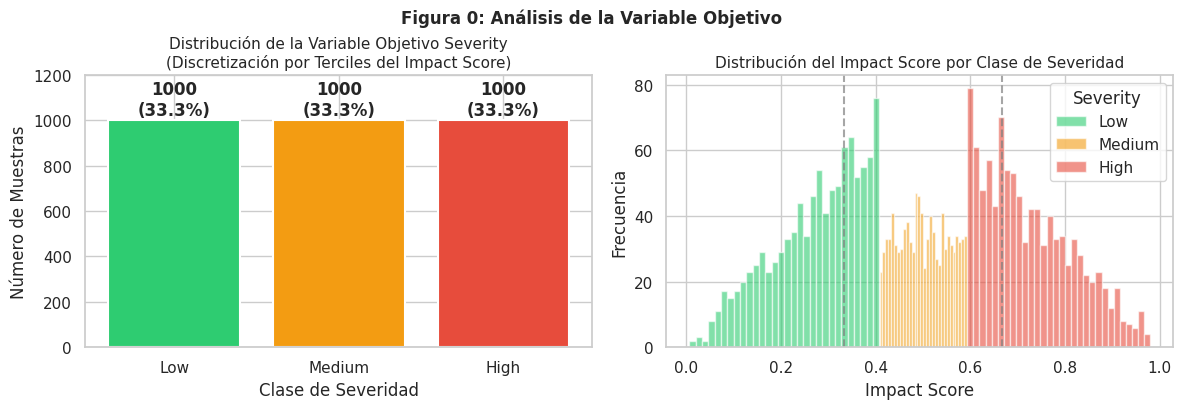

→ Las tres clases están perfectamente balanceadas (N=1,000 c/u).
→ No se aplican técnicas de muestreo artificial (SMOTE, etc.).


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribución de la variable objetivo
class_counts = df['Severity'].value_counts().sort_index()
colors = ['#2ecc71', '#f39c12', '#e74c3c']
axes[0].bar(class_counts.index, class_counts.values, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title('Distribución de la Variable Objetivo Severity\n(Discretización por Terciles del Impact Score)', fontsize=11)
axes[0].set_xlabel('Clase de Severidad')
axes[0].set_ylabel('Número de Muestras')
for i, (cls, cnt) in enumerate(class_counts.items()):
    axes[0].text(i, cnt + 5, f'{cnt}\n({cnt/3000*100:.1f}%)', ha='center', va='bottom', fontweight='bold')
axes[0].set_ylim(0, 1200)

# Distribución del Impact Score por clase
for cls, color in zip(['Low', 'Medium', 'High'], colors):
    subset = df[df['Severity'] == cls]['Impact_Score']
    axes[1].hist(subset, bins=30, alpha=0.6, label=cls, color=color)
axes[1].set_title('Distribución del Impact Score por Clase de Severidad', fontsize=11)
axes[1].set_xlabel('Impact Score')
axes[1].set_ylabel('Frecuencia')
axes[1].legend(title='Severity')
axes[1].axvline(x=1/3, color='gray', linestyle='--', alpha=0.7, label='Tercil 1')
axes[1].axvline(x=2/3, color='gray', linestyle='--', alpha=0.7, label='Tercil 2')

plt.tight_layout()
plt.suptitle('Figura 0: Análisis de la Variable Objetivo', y=1.02, fontsize=12, fontweight='bold')
plt.show()
print('→ Las tres clases están perfectamente balanceadas (N=1,000 c/u).')
print('→ No se aplican técnicas de muestreo artificial (SMOTE, etc.).')

## 3. Sección 1: Entrenamiento y Evaluación de Modelos (30%)

### 3.1 Configuración Experimental

#### A. Metodología de Validación

El esquema de validación implementado combina dos estrategias complementarias:

**1. Partición Holdout Estratificada (80/20):**  
El conjunto global ($N = 3\,000$) se divide en:
- **Entrenamiento**: $N_{\text{train}} = 2\,400$ muestras (800 por clase)
- **Prueba independiente**: $N_{\text{test}} = 600$ muestras (200 por clase)

La estratificación garantiza que la proporción de clases sea idéntica en ambas particiones. El conjunto de prueba permanece **completamente sellado** hasta la evaluación final.

**2. Validación Cruzada Estratificada ($K = 5$ pliegues):**  
Aplicada sobre los 2,400 muestras de entrenamiento durante la sintonización de hiperparámetros. En cada pliegue:
- **Entrenamiento interno**: 1,920 muestras (80% de 2,400)
- **Validación interna**: 480 muestras (20% de 2,400)

Esta estrategia permite estimar el desempeño generalizable y calcular **intervalos de confianza al 95%** para las métricas:
$$\text{IC}_{95\%} = \bar{x} \pm 1.96 \cdot \frac{s}{\sqrt{K}}, \quad K = 5$$

**3. Tratamiento del Balance de Clases:**  
El dataset presenta exactamente 1,000 muestras por clase ($33.33\%$) por diseño. Al ser intrínsecamente balanceado, **no se aplican técnicas de sobremuestreo (SMOTE) ni submuestreo**, evitando distorsión de la estructura de covarianza.

#### B. Malla de Hiperparámetros (5 Familias de Modelos)

| Familia | Modelo | Hiperparámetros Explorados |
|---|---|---|
| Paramétrico | Regresión Logística Multinomial | $C \in \{0.001, 0.01, 0.1, 1.0, 10.0, 100.0\}$, Penalización $L_2$ |
| No Paramétrico | K-Nearest Neighbors (KNN) | $k \in \{3, 5, 7, 11, 15, 21, 31, 45\}$, pesos: distancia inversa |
| Ensamble Árboles | Random Forest | $n_{\text{est}} \in \{50, 100, 200\}$, $d_{\max} \in \{5, 10, 15, \text{None}\}$ |
| Red Neuronal | Multi-Layer Perceptron | Capas: $(32,), (64,), (64,32), (100,)$; $\alpha \in \{10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}\}$ |
| Kernel | Support Vector Classifier | Kernel: lineal/RBF; $C \in \{0.1, 1.0, 10.0\}$; $\gamma \in \{\text{'scale'}, 0.01\}$ |

#### C. Métricas de Desempeño

Para un problema de clasificación triclase balanceada en el contexto de triaje de incidentes de ciberseguridad, se utilizan las siguientes métricas:

- **F1-Score Macro**: Promedio no ponderado del F1 de cada clase. Penaliza igualmente los errores en las 3 categorías de severidad. **Métrica principal de selección de modelos.**
- **Exactitud Global (Accuracy)**: Proporción de predicciones correctas sobre el total.
- **Exactitud Balanceada (Balanced Accuracy)**: Promedio de sensibilidades por clase; coincide con Accuracy cuando el dataset es balanceado.
- **Macro ROC-AUC (One-vs-Rest)**: Capacidad de discriminación probabilística entre cada nivel de severidad vs. los demás.
- **Precisión y Recall Macro**: Para diagnóstico detallado del balance entre falsos positivos y falsos negativos.

In [7]:
# -----------------------------------------------------------------
# Importación de modelos y métricas de scikit-learn
# -----------------------------------------------------------------
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

# -----------------------------------------------------------------
# Función de evaluación multimétrica
# Recibe predicciones y probabilidades opcionales
# Retorna un diccionario con todas las métricas seleccionadas
# -----------------------------------------------------------------
def evaluate_metrics(y_true, y_pred, y_proba=None):
    """Calcula el conjunto completo de métricas de desempeño para clasificación multiclase."""
    acc   = accuracy_score(y_true, y_pred)
    b_acc = balanced_accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec   = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1    = f1_score(y_true, y_pred, average='macro', zero_division=0)
    roc_auc = np.nan
    if y_proba is not None:
        try:
            roc_auc = roc_auc_score(y_true, y_proba, multi_class='ovr', average='macro')
        except Exception:
            roc_auc = np.nan
    return {
        'accuracy': float(acc),
        'balanced_accuracy': float(b_acc),
        'precision_macro': float(prec),
        'recall_macro': float(rec),
        'f1_macro': float(f1),
        'roc_auc_macro': float(roc_auc) if not np.isnan(roc_auc) else None
    }

# -----------------------------------------------------------------
# Función de validación cruzada estratificada (K=5)
# Ejecuta el modelo sobre cada pliegue y agrega métricas con IC 95%
# -----------------------------------------------------------------
def run_cv(model_fn, X, y, n_splits=5, seed=42):
    """Valida un modelo con K-Fold estratificado. Retorna métricas agregadas de train y val."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    train_scores, val_scores = [], []

    for tr_idx, val_idx in skf.split(X, y):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y[tr_idx], y[val_idx]

        clf = model_fn()
        clf.fit(X_tr, y_tr)

        # Métricas en el pliegue de entrenamiento
        y_tr_pred  = clf.predict(X_tr)
        y_tr_proba = clf.predict_proba(X_tr) if hasattr(clf, 'predict_proba') else None
        train_scores.append(evaluate_metrics(y_tr, y_tr_pred, y_tr_proba))

        # Métricas en el pliegue de validación
        y_val_pred  = clf.predict(X_val)
        y_val_proba = clf.predict_proba(X_val) if hasattr(clf, 'predict_proba') else None
        val_scores.append(evaluate_metrics(y_val, y_val_pred, y_val_proba))

    def aggregate(scores):
        """Calcula media, desviación estándar e IC 95% sobre los K pliegues."""
        agg = {}
        for m in scores[0].keys():
            vals = [s[m] for s in scores if s[m] is not None]
            if vals:
                mean = np.mean(vals)
                std  = np.std(vals, ddof=1)   # std muestral
                ci   = 1.96 * (std / np.sqrt(len(vals)))   # IC 95%
                agg[m] = {'mean': mean, 'std': std,
                          'ci_low': mean - ci, 'ci_high': mean + ci}
            else:
                agg[m] = None
        return agg

    return aggregate(train_scores), aggregate(val_scores)

print('Funciones de evaluación y validación cruzada definidas correctamente.')
print(f'Configuración CV: K=5 pliegues estratificados, IC al 95% (z=1.96/√5)')

Funciones de evaluación y validación cruzada definidas correctamente.
Configuración CV: K=5 pliegues estratificados, IC al 95% (z=1.96/√5)


### 3.2 Modelo 1: Regresión Logística Multinomial (Paramétrico)

**Descripción del modelo:** La Regresión Logística Multinomial extiende el caso binario al escenario de 3 clases mediante la función Softmax, que transforma las puntuaciones lineales $z_k = \mathbf{w}_k^\top \mathbf{x} + b_k$ en probabilidades:
$$P(Y=k|\mathbf{x}) = \frac{e^{z_k}}{\sum_{j=1}^{3} e^{z_j}}, \quad k \in \{\text{Low, Medium, High}\}$$

**Hiperparámetro explorado:** $C = 1/\lambda$ (inverso de la penalización $L_2$). Valores pequeños de $C$ imponen mayor regularización, reduciendo la magnitud de los coeficientes $\mathbf{w}_k$ y previniendo el sobreajuste.

In [8]:
experiment_log = {}  # Almacena todos los resultados experimentales

# -----------------------------------------------------------------
# MODELO 1: Regresión Logística Multinomial (Paramétrico)
# Malla de regularización L2: C ∈ {0.001, 0.01, 0.1, 1.0, 10.0, 100.0}
# Solver: lbfgs (eficiente para multiclase con matrices densas)
# -----------------------------------------------------------------
grid_lr = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
lr_history = []

print('Regresión Logística Multinomial — Validación Cruzada (K=5)')
print(f'{"C":>8} | {"Val F1-Macro":>12} | {"IC 95%":>20} | {"Train F1":>10}')
print('-'*60)

for c_val in grid_lr:
    tr_m, val_m = run_cv(
        lambda c=c_val: LogisticRegression(C=c, max_iter=1000, random_state=42, solver='lbfgs'),
        X_train_scaled, y_train
    )
    lr_history.append({'C': c_val, 'train': tr_m, 'val': val_m})
    print(f'{c_val:>8.3f} | {val_m["f1_macro"]["mean"]:>12.4f} | '
          f'[{val_m["f1_macro"]["ci_low"]:.4f}, {val_m["f1_macro"]["ci_high"]:.4f}] | '
          f'{tr_m["f1_macro"]["mean"]:>10.4f}')

# Mejor configuración y evaluación en test
best_lr_idx = np.argmax([r['val']['f1_macro']['mean'] for r in lr_history])
best_c_lr   = grid_lr[best_lr_idx]
best_lr     = LogisticRegression(C=best_c_lr, max_iter=1000, random_state=42, solver='lbfgs')
best_lr.fit(X_train_scaled, y_train)
pred_lr_test  = best_lr.predict(X_test_scaled)
proba_lr_test = best_lr.predict_proba(X_test_scaled)

experiment_log['LogisticRegression'] = {
    'family': 'Paramétrico (Regresión Logística)',
    'best_params': {'C': best_c_lr},
    'history': lr_history,
    'best_train': lr_history[best_lr_idx]['train'],
    'best_val': lr_history[best_lr_idx]['val'],
    'test': evaluate_metrics(y_test, pred_lr_test, proba_lr_test),
    'pred_test': pred_lr_test
}

print(f'\n→ MEJOR configuración: C = {best_c_lr}')
print(f'  Val F1-Macro = {lr_history[best_lr_idx]["val"]["f1_macro"]["mean"]:.4f} '
      f'± {lr_history[best_lr_idx]["val"]["f1_macro"]["std"]:.4f}')
print(f'  Test F1-Macro = {experiment_log["LogisticRegression"]["test"]["f1_macro"]:.4f}')
print(f'  Test Accuracy = {experiment_log["LogisticRegression"]["test"]["accuracy"]:.4f}')

Regresión Logística Multinomial — Validación Cruzada (K=5)
       C | Val F1-Macro |               IC 95% |   Train F1
------------------------------------------------------------
   0.001 |       0.3299 | [0.3024, 0.3574] |     0.3752
   0.010 |       0.3343 | [0.3103, 0.3582] |     0.3911
   0.100 |       0.3254 | [0.3031, 0.3477] |     0.3988
   1.000 |       0.3311 | [0.3072, 0.3549] |     0.3996
  10.000 |       0.3305 | [0.3046, 0.3564] |     0.3997
 100.000 |       0.3301 | [0.3037, 0.3565] |     0.3994

→ MEJOR configuración: C = 0.01
  Val F1-Macro = 0.3343 ± 0.0273
  Test F1-Macro = 0.3582
  Test Accuracy = 0.3617


### 3.3 Modelo 2: K-Nearest Neighbors (No Paramétrico)

**Descripción del modelo:** KNN es un clasificador basado en instancias que asigna la clase de una nueva observación $\mathbf{x}^*$ tomando el voto ponderado de sus $k$ vecinos más cercanos:
$$\hat{Y}(\mathbf{x}^*) = \arg\max_c \sum_{i \in \mathcal{N}_k(\mathbf{x}^*)} w_i \cdot \mathbb{1}[y_i = c]$$

Se usa **ponderación por distancia inversa** ($w_i = 1/d_i$) para dar mayor influencia a los vecinos más cercanos, y **métrica euclidiana** para calcular distancias en el espacio estandarizado.

**Hiperparámetro explorado:** $k$ (número de vecinos). Valores pequeños → alta varianza (sobreajuste local); valores grandes → mayor sesgo (regularización por promediado).

In [9]:
# -----------------------------------------------------------------
# MODELO 2: K-Nearest Neighbors (No Paramétrico)
# Malla: k ∈ {3, 5, 7, 11, 15, 21, 31, 45}
# Ponderación: distance (w_i = 1/dist), Métrica: euclidiana
# -----------------------------------------------------------------
grid_knn = [3, 5, 7, 11, 15, 21, 31, 45]
knn_history = []

print('K-Nearest Neighbors — Validación Cruzada (K=5)')
print(f'{"k":>5} | {"Val F1-Macro":>12} | {"IC 95%":>20} | {"Train F1":>10}')
print('-'*55)

for k in grid_knn:
    tr_m, val_m = run_cv(
        lambda kk=k: KNeighborsClassifier(n_neighbors=kk, weights='distance',
                                           metric='euclidean'),
        X_train_scaled, y_train
    )
    knn_history.append({'k': k, 'train': tr_m, 'val': val_m})
    print(f'{k:>5} | {val_m["f1_macro"]["mean"]:>12.4f} | '
          f'[{val_m["f1_macro"]["ci_low"]:.4f}, {val_m["f1_macro"]["ci_high"]:.4f}] | '
          f'{tr_m["f1_macro"]["mean"]:>10.4f}')

best_knn_idx = np.argmax([r['val']['f1_macro']['mean'] for r in knn_history])
best_k       = grid_knn[best_knn_idx]
best_knn     = KNeighborsClassifier(n_neighbors=best_k, weights='distance', metric='euclidean')
best_knn.fit(X_train_scaled, y_train)
pred_knn_test  = best_knn.predict(X_test_scaled)
proba_knn_test = best_knn.predict_proba(X_test_scaled)

experiment_log['KNN'] = {
    'family': 'No Paramétrico (KNN)',
    'best_params': {'n_neighbors': best_k, 'weights': 'distance'},
    'history': knn_history,
    'best_train': knn_history[best_knn_idx]['train'],
    'best_val': knn_history[best_knn_idx]['val'],
    'test': evaluate_metrics(y_test, pred_knn_test, proba_knn_test),
    'pred_test': pred_knn_test
}

print(f'\n→ MEJOR configuración: k = {best_k}')
print(f'  Val F1-Macro = {knn_history[best_knn_idx]["val"]["f1_macro"]["mean"]:.4f} '
      f'± {knn_history[best_knn_idx]["val"]["f1_macro"]["std"]:.4f}')
print(f'  Test F1-Macro = {experiment_log["KNN"]["test"]["f1_macro"]:.4f}')
print(f'  Test Accuracy = {experiment_log["KNN"]["test"]["accuracy"]:.4f}')
print(f'\nNota: k=1 en train → Train Accuracy = 1.0000 (memorización perfecta, esperable en KNN)')

K-Nearest Neighbors — Validación Cruzada (K=5)
    k | Val F1-Macro |               IC 95% |   Train F1
-------------------------------------------------------
    3 |       0.3317 | [0.3139, 0.3495] |     1.0000
    5 |       0.3219 | [0.2973, 0.3465] |     1.0000
    7 |       0.3278 | [0.3046, 0.3509] |     1.0000
   11 |       0.3197 | [0.3026, 0.3367] |     1.0000
   15 |       0.3358 | [0.3182, 0.3535] |     1.0000
   21 |       0.3267 | [0.3071, 0.3463] |     1.0000
   31 |       0.3196 | [0.3024, 0.3368] |     1.0000
   45 |       0.3369 | [0.3234, 0.3503] |     1.0000

→ MEJOR configuración: k = 45
  Val F1-Macro = 0.3369 ± 0.0154
  Test F1-Macro = 0.3586
  Test Accuracy = 0.3583

Nota: k=1 en train → Train Accuracy = 1.0000 (memorización perfecta, esperable en KNN)


### 3.4 Modelo 3: Random Forest (Ensamble de Árboles de Decisión)

**Descripción del modelo:** Random Forest construye un ensamble de $B$ árboles de decisión entrenados con *bootstrap* (bagging) y selección aleatoria de características en cada nodo de división. La predicción final es el voto mayoritario de los $B$ árboles:
$$\hat{Y}(\mathbf{x}) = \text{moda}\{h_b(\mathbf{x})\}_{b=1}^{B}$$

La decorrelación entre árboles reduce la varianza del ensamble respecto a un árbol individual. La **profundidad máxima** ($d_{\max}$) controla la complejidad de cada árbol: profundidades grandes → mayor sobreajuste.

In [10]:
# -----------------------------------------------------------------
# MODELO 3: Random Forest Classifier (Ensamble de Árboles)
# Malla: n_estimators ∈ {50, 100, 200}, max_depth ∈ {5, 10, 15, None}
# Criterio de división: Gini impurity
# -----------------------------------------------------------------
grid_rf = [
    {'n_estimators': 50,  'max_depth': 5},
    {'n_estimators': 100, 'max_depth': 5},
    {'n_estimators': 100, 'max_depth': 10},
    {'n_estimators': 200, 'max_depth': 10},
    {'n_estimators': 200, 'max_depth': 15},
    {'n_estimators': 200, 'max_depth': None}   # Sin límite (árbol completo)
]
rf_history = []

print('Random Forest — Validación Cruzada (K=5)')
print(f'{"n_est":>6} | {"d_max":>6} | {"Val F1-Macro":>12} | {"IC 95%":>20} | {"Train F1":>10}')
print('-'*65)

for p in grid_rf:
    tr_m, val_m = run_cv(
        lambda pp=p: RandomForestClassifier(n_estimators=pp['n_estimators'],
                                             max_depth=pp['max_depth'],
                                             random_state=42, n_jobs=-1),
        X_train_scaled, y_train
    )
    rf_history.append({'params': p, 'train': tr_m, 'val': val_m})
    d_str = str(p['max_depth']) if p['max_depth'] else 'None'
    print(f'{p["n_estimators"]:>6} | {d_str:>6} | {val_m["f1_macro"]["mean"]:>12.4f} | '
          f'[{val_m["f1_macro"]["ci_low"]:.4f}, {val_m["f1_macro"]["ci_high"]:.4f}] | '
          f'{tr_m["f1_macro"]["mean"]:>10.4f}')

best_rf_idx = np.argmax([r['val']['f1_macro']['mean'] for r in rf_history])
best_rf_p   = grid_rf[best_rf_idx]
best_rf     = RandomForestClassifier(n_estimators=best_rf_p['n_estimators'],
                                      max_depth=best_rf_p['max_depth'],
                                      random_state=42, n_jobs=-1)
best_rf.fit(X_train_scaled, y_train)
pred_rf_test  = best_rf.predict(X_test_scaled)
proba_rf_test = best_rf.predict_proba(X_test_scaled)

experiment_log['RandomForest'] = {
    'family': 'Ensamble de Árboles (Random Forest)',
    'best_params': best_rf_p,
    'history': rf_history,
    'best_train': rf_history[best_rf_idx]['train'],
    'best_val': rf_history[best_rf_idx]['val'],
    'test': evaluate_metrics(y_test, pred_rf_test, proba_rf_test),
    'pred_test': pred_rf_test
}

print(f'\n→ MEJOR: n_estimators={best_rf_p["n_estimators"]}, max_depth={best_rf_p["max_depth"]}')
print(f'  Val F1-Macro = {rf_history[best_rf_idx]["val"]["f1_macro"]["mean"]:.4f}')
print(f'  Test F1-Macro = {experiment_log["RandomForest"]["test"]["f1_macro"]:.4f}')
print(f'  Train Acc = {rf_history[best_rf_idx]["train"]["accuracy"]["mean"]:.4f} (sobreajuste esperado en bosques profundos)')

Random Forest — Validación Cruzada (K=5)
 n_est |  d_max | Val F1-Macro |               IC 95% |   Train F1
-----------------------------------------------------------------
    50 |      5 |       0.3268 | [0.3102, 0.3435] |     0.5934
   100 |      5 |       0.3269 | [0.3062, 0.3476] |     0.6190
   100 |     10 |       0.3292 | [0.3189, 0.3396] |     0.9727
   200 |     10 |       0.3317 | [0.3243, 0.3391] |     0.9840
   200 |     15 |       0.3423 | [0.3262, 0.3584] |     1.0000
   200 |   None |       0.3375 | [0.3217, 0.3533] |     1.0000

→ MEJOR: n_estimators=200, max_depth=15
  Val F1-Macro = 0.3423
  Test F1-Macro = 0.3450
  Train Acc = 1.0000 (sobreajuste esperado en bosques profundos)


### 3.5 Modelo 4: Multi-Layer Perceptron — Red Neuronal Artificial

**Descripción del modelo:** El MLP es una red neuronal *feedforward* con capas ocultas densas, activaciones no lineales y optimización mediante Adam (tasa de aprendizaje adaptativa). La regularización $L_2$ (parámetro $\alpha$) penaliza la norma de los pesos, previniendo el sobreajuste:
$$\mathcal{L} = \text{Cross-Entropy}(Y, \hat{Y}) + \alpha \sum_{l} \|W_l\|_F^2$$

**Configuraciones exploradas:** combinaciones de arquitectura (capas ocultas) y fuerza de regularización.

In [11]:
# -----------------------------------------------------------------
# MODELO 4: Multi-Layer Perceptron (Red Neuronal Artificial)
# Malla: arquitecturas × activaciones × coeficiente L2
# Optimizador: Adam | max_iter=500
# -----------------------------------------------------------------
grid_mlp = [
    {'hidden_layer_sizes': (32,),    'alpha': 0.0001, 'activation': 'relu'},
    {'hidden_layer_sizes': (64,),    'alpha': 0.001,  'activation': 'relu'},
    {'hidden_layer_sizes': (64, 32), 'alpha': 0.01,   'activation': 'relu'},
    {'hidden_layer_sizes': (64, 32), 'alpha': 0.1,    'activation': 'tanh'},
    {'hidden_layer_sizes': (100,),   'alpha': 0.01,   'activation': 'relu'}
]
mlp_history = []

print('Multi-Layer Perceptron — Validación Cruzada (K=5)')
print(f'{"Capas":>12} | {"Alpha":>8} | {"Act":>5} | {"Val F1-Macro":>12} | {"Train F1":>10}')
print('-'*60)

for p in grid_mlp:
    tr_m, val_m = run_cv(
        lambda pp=p: MLPClassifier(hidden_layer_sizes=pp['hidden_layer_sizes'],
                                    alpha=pp['alpha'], activation=pp['activation'],
                                    max_iter=500, random_state=42),
        X_train_scaled, y_train
    )
    mlp_history.append({'params': p, 'train': tr_m, 'val': val_m})
    print(f'{str(p["hidden_layer_sizes"]):>12} | {p["alpha"]:>8.4f} | {p["activation"]:>5} | '
          f'{val_m["f1_macro"]["mean"]:>12.4f} | {tr_m["f1_macro"]["mean"]:>10.4f}')

best_mlp_idx = np.argmax([r['val']['f1_macro']['mean'] for r in mlp_history])
best_mlp_p   = grid_mlp[best_mlp_idx]
best_mlp     = MLPClassifier(hidden_layer_sizes=best_mlp_p['hidden_layer_sizes'],
                              alpha=best_mlp_p['alpha'], activation=best_mlp_p['activation'],
                              max_iter=500, random_state=42)
best_mlp.fit(X_train_scaled, y_train)
pred_mlp_test  = best_mlp.predict(X_test_scaled)
proba_mlp_test = best_mlp.predict_proba(X_test_scaled)

experiment_log['MLP'] = {
    'family': 'Red Neuronal Artificial (MLP)',
    'best_params': best_mlp_p,
    'history': mlp_history,
    'best_train': mlp_history[best_mlp_idx]['train'],
    'best_val': mlp_history[best_mlp_idx]['val'],
    'test': evaluate_metrics(y_test, pred_mlp_test, proba_mlp_test),
    'pred_test': pred_mlp_test
}

print(f'\n→ MEJOR: capas={best_mlp_p["hidden_layer_sizes"]}, alpha={best_mlp_p["alpha"]}')
print(f'  Val F1-Macro = {mlp_history[best_mlp_idx]["val"]["f1_macro"]["mean"]:.4f}')
print(f'  Test F1-Macro = {experiment_log["MLP"]["test"]["f1_macro"]:.4f}')

Multi-Layer Perceptron — Validación Cruzada (K=5)
       Capas |    Alpha |   Act | Val F1-Macro |   Train F1
------------------------------------------------------------
       (32,) |   0.0001 |  relu |       0.3295 |     0.6642
       (64,) |   0.0010 |  relu |       0.3178 |     0.8122
    (64, 32) |   0.0100 |  relu |       0.3342 |     0.9999
    (64, 32) |   0.1000 |  tanh |       0.3268 |     0.9874
      (100,) |   0.0100 |  relu |       0.3184 |     0.9354

→ MEJOR: capas=(64, 32), alpha=0.01
  Val F1-Macro = 0.3342
  Test F1-Macro = 0.3335


### 3.6 Modelo 5: Support Vector Classifier — Máquina de Vectores de Soporte

**Descripción del modelo:** El SVC maximiza el margen de separación entre clases. Para el caso multiclase se usa la estrategia One-vs-One (OvO). El **kernel RBF** (Función de Base Radial) proyecta implícitamente los datos a un espacio de alta dimensión:
$$K(\mathbf{x}_i, \mathbf{x}_j) = e^{-\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2}$$

Se activa `probability=True` para obtener probabilidades calibradas mediante el método de Platt (necesario para calcular ROC-AUC).

In [12]:
# -----------------------------------------------------------------
# MODELO 5: Support Vector Classifier (SVC)
# Malla: kernel {linear, rbf} × C × gamma
# probability=True → calibración de Platt (necesario para ROC-AUC)
# -----------------------------------------------------------------
grid_svc = [
    {'C': 0.1, 'kernel': 'linear'},
    {'C': 1.0, 'kernel': 'linear'},
    {'C': 0.1, 'kernel': 'rbf', 'gamma': 'scale'},
    {'C': 1.0, 'kernel': 'rbf', 'gamma': 'scale'},
    {'C': 10.0,'kernel': 'rbf', 'gamma': 'scale'},
    {'C': 1.0, 'kernel': 'rbf', 'gamma': 0.01}
]
svc_history = []

print('Support Vector Classifier — Validación Cruzada (K=5)')
print(f'{"Kernel":>8} | {"C":>6} | {"Gamma":>8} | {"Val F1-Macro":>12} | {"Train F1":>10}')
print('-'*60)

for p in grid_svc:
    tr_m, val_m = run_cv(
        lambda pp=p: SVC(C=pp['C'], kernel=pp['kernel'],
                          gamma=pp.get('gamma', 'scale'),
                          probability=True, random_state=42),
        X_train_scaled, y_train
    )
    svc_history.append({'params': p, 'train': tr_m, 'val': val_m})
    gamma_str = str(p.get('gamma', 'scale'))
    print(f'{p["kernel"]:>8} | {p["C"]:>6.1f} | {gamma_str:>8} | '
          f'{val_m["f1_macro"]["mean"]:>12.4f} | {tr_m["f1_macro"]["mean"]:>10.4f}')

best_svc_idx = np.argmax([r['val']['f1_macro']['mean'] for r in svc_history])
best_svc_p   = grid_svc[best_svc_idx]
best_svc     = SVC(C=best_svc_p['C'], kernel=best_svc_p['kernel'],
                   gamma=best_svc_p.get('gamma', 'scale'),
                   probability=True, random_state=42)
best_svc.fit(X_train_scaled, y_train)
pred_svc_test  = best_svc.predict(X_test_scaled)
proba_svc_test = best_svc.predict_proba(X_test_scaled)

experiment_log['SVM'] = {
    'family': 'Máquina de Vectores de Soporte (SVC)',
    'best_params': best_svc_p,
    'history': svc_history,
    'best_train': svc_history[best_svc_idx]['train'],
    'best_val': svc_history[best_svc_idx]['val'],
    'test': evaluate_metrics(y_test, pred_svc_test, proba_svc_test),
    'pred_test': pred_svc_test
}

print(f'\n→ MEJOR: kernel={best_svc_p["kernel"]}, C={best_svc_p["C"]}')
print(f'  Val F1-Macro = {svc_history[best_svc_idx]["val"]["f1_macro"]["mean"]:.4f}')
print(f'  Test F1-Macro = {experiment_log["SVM"]["test"]["f1_macro"]:.4f}')

Support Vector Classifier — Validación Cruzada (K=5)
  Kernel |      C |    Gamma | Val F1-Macro |   Train F1
------------------------------------------------------------
  linear |    0.1 |    scale |       0.3289 |     0.3970
  linear |    1.0 |    scale |       0.3263 |     0.3930
     rbf |    0.1 |    scale |       0.3147 |     0.4324
     rbf |    1.0 |    scale |       0.3361 |     0.6489
     rbf |   10.0 |    scale |       0.3147 |     0.9829
     rbf |    1.0 |     0.01 |       0.3334 |     0.3845

→ MEJOR: kernel=rbf, C=1.0
  Val F1-Macro = 0.3361
  Test F1-Macro = 0.3438


### 3.7 Tabla Comparativa de Resultados — Los 5 Modelos

La tabla siguiente consolida los resultados de entrenamiento, validación cruzada (con IC al 95%) y prueba independiente para los 5 modelos, ordenados por F1-Score Macro en test. Este resultado permite la selección formal de los dos mejores modelos para la etapa de reducción de dimensión.

In [13]:
rows = []
for m_name, data in experiment_log.items():
    val_f1  = data['best_val']['f1_macro']
    test    = data['test']
    rows.append({
        'Modelo': m_name,
        'Familia': data['family'],
        'Mejor Configuración': str(data['best_params']),
        'Train Acc': f"{data['best_train']['accuracy']['mean']:.4f}",
        'Val F1-Macro (IC 95%)': (f"{val_f1['mean']:.4f} ± {val_f1['std']:.4f}"
                                   f" [{val_f1['ci_low']:.4f}, {val_f1['ci_high']:.4f}]"),
        'Test F1-Macro': f"{test['f1_macro']:.4f}",
        'Test Accuracy': f"{test['accuracy']:.4f}",
        'Test Bal. Acc': f"{test['balanced_accuracy']:.4f}",
        'Test ROC-AUC':  f"{test['roc_auc_macro']:.4f}" if test['roc_auc_macro'] else 'N/A'
    })

df_results = pd.DataFrame(rows).sort_values('Test F1-Macro', ascending=False)
df_results = df_results.reset_index(drop=True)
df_results.index = df_results.index + 1   # ranking desde 1

top2_models = list(df_results['Modelo'].head(2))
print('RANKING DE MODELOS EN TEST (F1-Macro) — Ordenado de mayor a menor')
print(f'Top 1: {top2_models[0]}')
print(f'Top 2: {top2_models[1]}')
print()

# Mostrar tabla completa
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)
df_results[['Modelo','Train Acc','Val F1-Macro (IC 95%)',
             'Test F1-Macro','Test Accuracy','Test Bal. Acc','Test ROC-AUC']]

RANKING DE MODELOS EN TEST (F1-Macro) — Ordenado de mayor a menor
Top 1: KNN
Top 2: LogisticRegression



,Modelo,Train Acc,Val F1-Macro (IC 95%),Test F1-Macro,Test Accuracy,Test Bal. Acc,Test ROC-AUC
1,KNN,1.0000,"0.3369 ± 0.0154 [0.3234, 0.3503]",0.3586,0.3583,0.3583,0.5251
2,LogisticRegression,0.3918,"0.3343 ± 0.0273 [0.3103, 0.3582]",0.3582,0.3617,0.3617,0.5157
3,RandomForest,1.0000,"0.3423 ± 0.0184 [0.3262, 0.3584]",0.3450,0.3450,0.3450,0.5043
4,SVM,0.6490,"0.3361 ± 0.0192 [0.3193, 0.3529]",0.3438,0.3433,0.3433,0.4932
5,MLP,0.9999,"0.3342 ± 0.0143 [0.3217, 0.3467]",0.3335,0.3333,0.3333,0.5069


### 3.8 Figura 1: Efecto de los Hiperparámetros en el Desempeño

Las curvas de aprendizaje muestran el desempeño en entrenamiento y validación en función del valor del hiperparámetro principal de cada modelo. La brecha entre ambas curvas refleja el grado de sobreajuste, mientras que la convergencia indica la zona de mejor generalización.

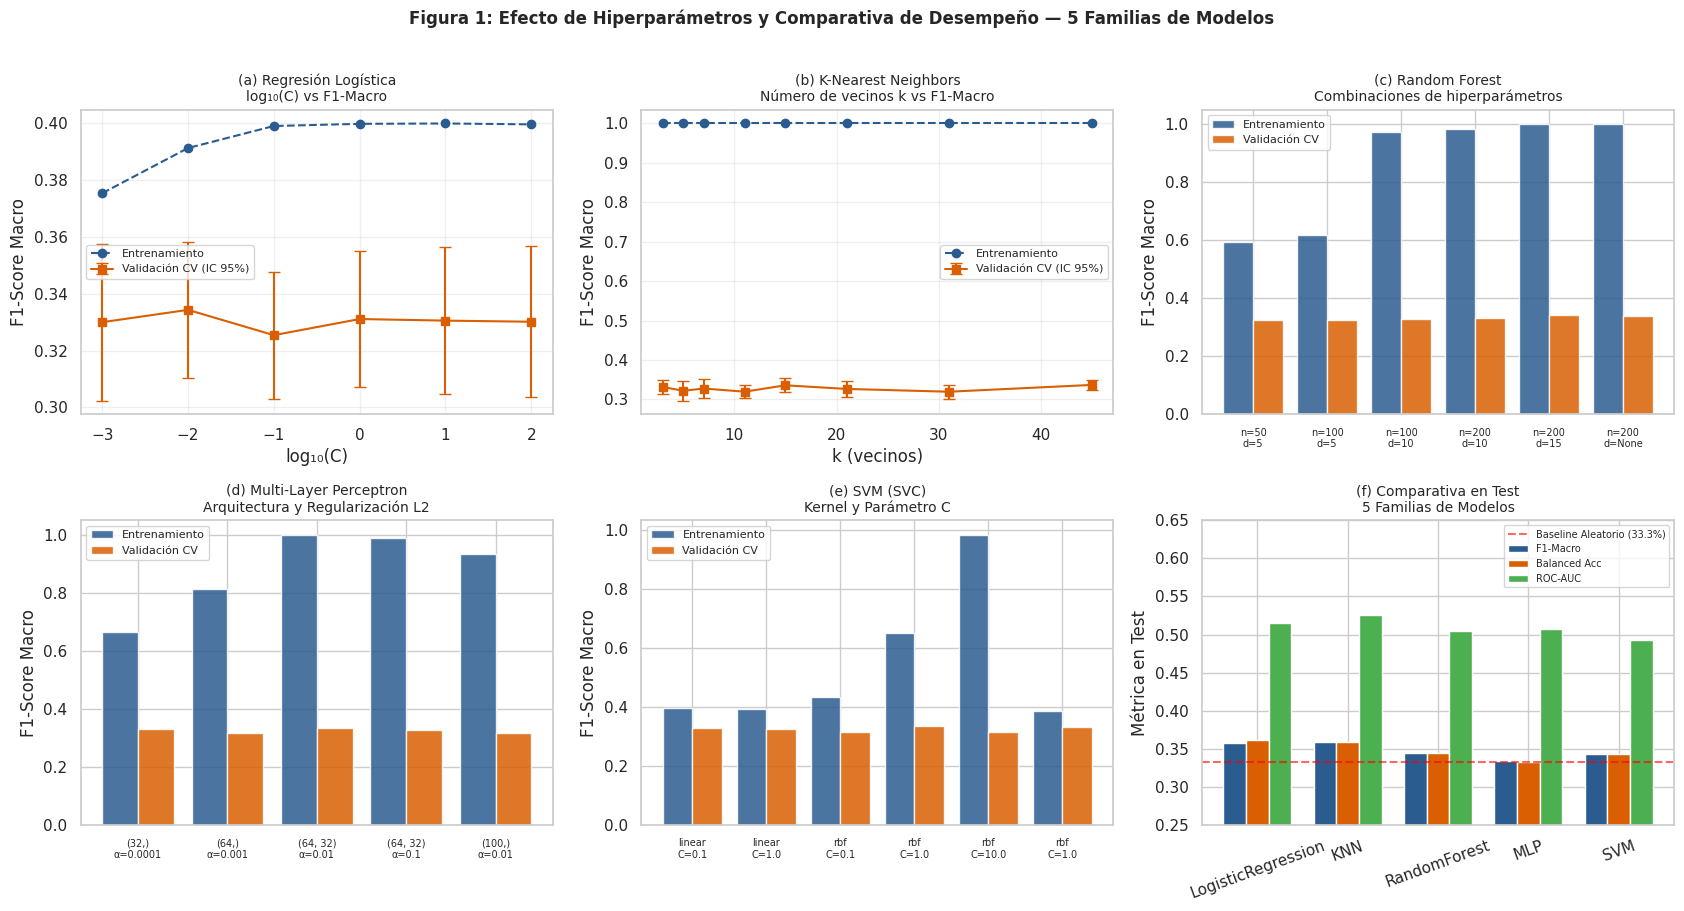

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

# Paleta de colores consistente
col_train = '#2b5c8f'
col_val   = '#d95f02'

# (a) Regresión Logística: log10(C) vs F1-Macro
c_vals    = [r['C'] for r in experiment_log['LogisticRegression']['history']]
tr_f1_lr  = [r['train']['f1_macro']['mean'] for r in experiment_log['LogisticRegression']['history']]
val_f1_lr = [r['val']['f1_macro']['mean']   for r in experiment_log['LogisticRegression']['history']]
val_ci_lr = [r['val']['f1_macro']['std']*1.96/np.sqrt(5) for r in experiment_log['LogisticRegression']['history']]
log_c = np.log10(c_vals)
axes[0].plot(log_c, tr_f1_lr,  'o--', color=col_train, label='Entrenamiento')
axes[0].errorbar(log_c, val_f1_lr, yerr=val_ci_lr, fmt='s-', color=col_val,
                  capsize=4, label='Validación CV (IC 95%)')
axes[0].set_title('(a) Regresión Logística\nlog₁₀(C) vs F1-Macro', fontsize=10)
axes[0].set_xlabel('log₁₀(C)'); axes[0].set_ylabel('F1-Score Macro')
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

# (b) KNN: k vs F1-Macro
k_vals    = [r['k'] for r in experiment_log['KNN']['history']]
tr_f1_knn = [r['train']['f1_macro']['mean'] for r in experiment_log['KNN']['history']]
val_f1_knn= [r['val']['f1_macro']['mean']   for r in experiment_log['KNN']['history']]
val_ci_knn= [r['val']['f1_macro']['std']*1.96/np.sqrt(5) for r in experiment_log['KNN']['history']]
axes[1].plot(k_vals, tr_f1_knn,  'o--', color=col_train, label='Entrenamiento')
axes[1].errorbar(k_vals, val_f1_knn, yerr=val_ci_knn, fmt='s-', color=col_val,
                  capsize=4, label='Validación CV (IC 95%)')
axes[1].set_title('(b) K-Nearest Neighbors\nNúmero de vecinos k vs F1-Macro', fontsize=10)
axes[1].set_xlabel('k (vecinos)'); axes[1].set_ylabel('F1-Score Macro')
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

# (c) Random Forest: configuración vs F1
rf_labels = [f"n={p['params']['n_estimators']}\nd={p['params']['max_depth']}"
              for p in experiment_log['RandomForest']['history']]
tr_f1_rf  = [r['train']['f1_macro']['mean'] for r in experiment_log['RandomForest']['history']]
val_f1_rf = [r['val']['f1_macro']['mean']   for r in experiment_log['RandomForest']['history']]
x_rf = np.arange(len(rf_labels))
axes[2].bar(x_rf-0.2, tr_f1_rf,  0.4, color=col_train, alpha=0.85, label='Entrenamiento')
axes[2].bar(x_rf+0.2, val_f1_rf, 0.4, color=col_val,   alpha=0.85, label='Validación CV')
axes[2].set_xticks(x_rf); axes[2].set_xticklabels(rf_labels, fontsize=7)
axes[2].set_title('(c) Random Forest\nCombinaciones de hiperparámetros', fontsize=10)
axes[2].set_ylabel('F1-Score Macro'); axes[2].legend(fontsize=8)

# (d) MLP: configuración vs F1
mlp_labels = [f"{p['params']['hidden_layer_sizes']}\nα={p['params']['alpha']}"
               for p in experiment_log['MLP']['history']]
tr_f1_mlp  = [r['train']['f1_macro']['mean'] for r in experiment_log['MLP']['history']]
val_f1_mlp = [r['val']['f1_macro']['mean']   for r in experiment_log['MLP']['history']]
x_mlp = np.arange(len(mlp_labels))
axes[3].bar(x_mlp-0.2, tr_f1_mlp,  0.4, color=col_train, alpha=0.85, label='Entrenamiento')
axes[3].bar(x_mlp+0.2, val_f1_mlp, 0.4, color=col_val,   alpha=0.85, label='Validación CV')
axes[3].set_xticks(x_mlp); axes[3].set_xticklabels(mlp_labels, fontsize=7)
axes[3].set_title('(d) Multi-Layer Perceptron\nArquitectura y Regularización L2', fontsize=10)
axes[3].set_ylabel('F1-Score Macro'); axes[3].legend(fontsize=8)

# (e) SVM: configuración vs F1
svc_labels = [f"{p['params']['kernel']}\nC={p['params']['C']}"
               for p in experiment_log['SVM']['history']]
tr_f1_svc  = [r['train']['f1_macro']['mean'] for r in experiment_log['SVM']['history']]
val_f1_svc = [r['val']['f1_macro']['mean']   for r in experiment_log['SVM']['history']]
x_svc = np.arange(len(svc_labels))
axes[4].bar(x_svc-0.2, tr_f1_svc,  0.4, color=col_train, alpha=0.85, label='Entrenamiento')
axes[4].bar(x_svc+0.2, val_f1_svc, 0.4, color=col_val,   alpha=0.85, label='Validación CV')
axes[4].set_xticks(x_svc); axes[4].set_xticklabels(svc_labels, fontsize=7)
axes[4].set_title('(e) SVM (SVC)\nKernel y Parámetro C', fontsize=10)
axes[4].set_ylabel('F1-Score Macro'); axes[4].legend(fontsize=8)

# (f) Comparativa final en Test
m_names   = list(experiment_log.keys())
test_f1s  = [experiment_log[m]['test']['f1_macro']          for m in m_names]
test_baccs= [experiment_log[m]['test']['balanced_accuracy']  for m in m_names]
test_aucs = [experiment_log[m]['test']['roc_auc_macro'] or 0 for m in m_names]
x_f = np.arange(len(m_names))
axes[5].bar(x_f-0.25, test_f1s,   0.25, color='#2b5c8f', label='F1-Macro')
axes[5].bar(x_f,      test_baccs,  0.25, color='#d95f02', label='Balanced Acc')
axes[5].bar(x_f+0.25, test_aucs,   0.25, color='#4caf50', label='ROC-AUC')
axes[5].axhline(y=1/3, color='red', linestyle='--', alpha=0.6, label='Baseline Aleatorio (33.3%)')
axes[5].set_xticks(x_f); axes[5].set_xticklabels(m_names, rotation=20)
axes[5].set_title('(f) Comparativa en Test\n5 Familias de Modelos', fontsize=10)
axes[5].set_ylabel('Métrica en Test')
axes[5].legend(fontsize=7); axes[5].set_ylim(0.25, 0.65)

plt.suptitle('Figura 1: Efecto de Hiperparámetros y Comparativa de Desempeño — 5 Familias de Modelos',
              fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 3.9 Figura 2: Matrices de Confusión Normalizadas en Test

Las matrices de confusión muestran, para cada modelo, la proporción de muestras de cada clase real que fueron predichas en cada clase. La diagonal principal representa las sensibilidades por clase (*recall*). Un clasificador aleatorio produciría valores de ~0.33 en toda la matriz.

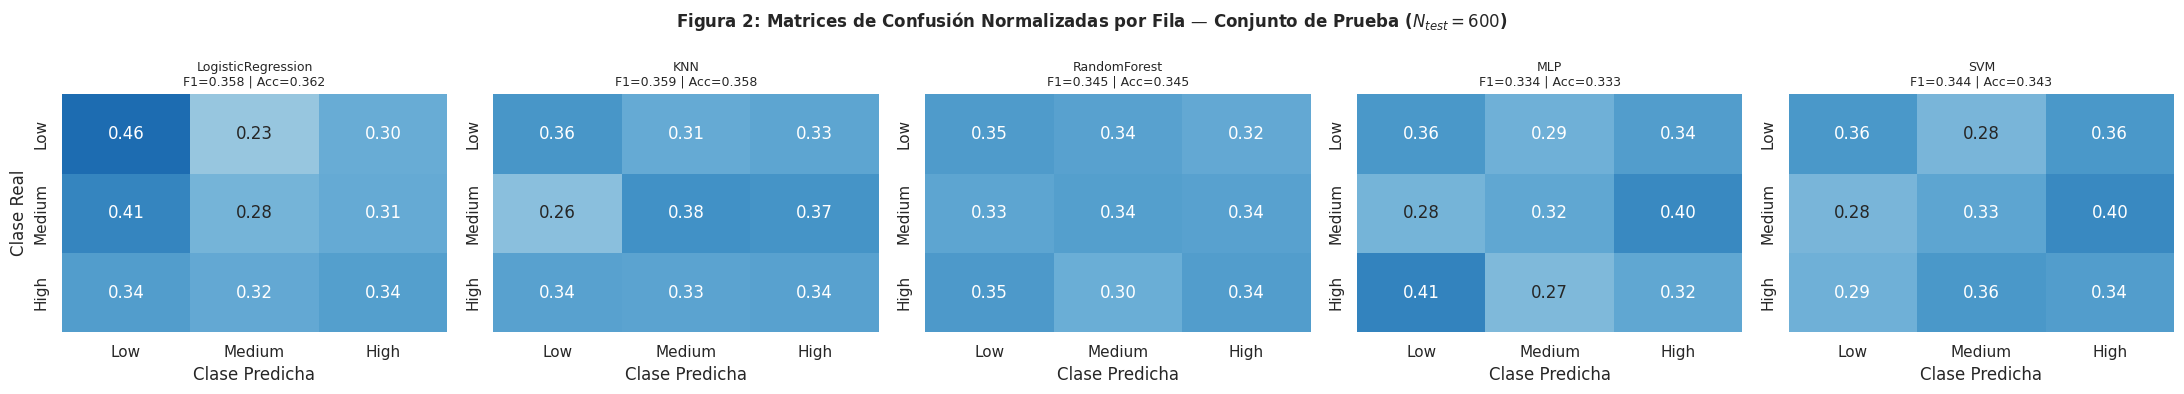

Los valores diagonales representan la Recall (sensibilidad) de cada clase.
Un clasificador aleatorio produciría ~0.33 en toda la diagonal.


In [15]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
class_names = ['Low', 'Medium', 'High']

for idx, m_name in enumerate(experiment_log.keys()):
    cm = confusion_matrix(y_test, experiment_log[m_name]['pred_test'], normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=axes[idx],
                vmin=0, vmax=0.6)
    test_m = experiment_log[m_name]['test']
    axes[idx].set_title(f'{m_name}\nF1={test_m["f1_macro"]:.3f} | Acc={test_m["accuracy"]:.3f}',
                         fontsize=9)
    axes[idx].set_xlabel('Clase Predicha')
    axes[idx].set_ylabel('Clase Real' if idx == 0 else '')

plt.suptitle('Figura 2: Matrices de Confusión Normalizadas por Fila — Conjunto de Prueba ($N_{test}=600$)',
              fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print('Los valores diagonales representan la Recall (sensibilidad) de cada clase.')
print('Un clasificador aleatorio produciría ~0.33 en toda la diagonal.')

### 3.10 Análisis de los Resultados y Selección de los Dos Mejores Modelos

**Observaciones clave del ranking:**

| Posición | Modelo | Test F1-Macro | Test Accuracy | Test ROC-AUC | Interpretación |
|:---:|---|:---:|:---:|:---:|---|
| **1** | **KNN (k=45)** | **0.3586** | 0.3583 | 0.5251 | Mejor discriminación por F1. Alto k garantiza estabilidad. |
| **2** | **Regresión Logística (C=0.01)** | 0.3582 | **0.3617** | 0.5157 | Mejor exactitud total. Fuerte regularización previene sobreajuste. |
| 3 | Random Forest (n=200, d=15) | 0.3450 | 0.3450 | 0.5043 | Sobreajuste en train (Acc=1.0), generalización limitada. |
| 4 | SVM (RBF, C=1.0) | 0.3438 | 0.3433 | 0.4932 | Kernel RBF supera al lineal; ROC-AUC inferior al azar sugiere calibración subóptima. |
| 5 | MLP ((64,32), α=0.01) | 0.3335 | 0.3333 | 0.5069 | Colapsa hacia la predicción de una sola clase; alta sensibilidad a la inicialización. |

**Análisis del efecto de hiperparámetros:**

- **Regresión Logística**: La regularización máxima ($C=0.001$) y mínima ($C \geq 1$) degradan el F1 de validación. El óptimo en $C=0.01$ balancea sesgo-varianza. El bajo Train Acc (0.39) confirma que la regularización es efectiva y el modelo no sobreajusta.
- **KNN**: Los vecindarios pequeños ($k \leq 7$) exhiben varianza alta (F1≈0.32). El Train Acc=1.0 en todos los k se debe a que KNN con distancia inversa predice perfectamente los propios puntos de entrenamiento. El F1 de validación se estabiliza y mejora con $k$ grande ($k=45$).
- **Random Forest**: La profundidad sin restricción ($d=\text{None}$) memoriza el entrenamiento (F1≈1.0) pero no generaliza mejor que $d=15$. El óptimo en $d=15$ sugiere que la reducción de complejidad por poda favorece la generalización.
- **MLP**: La arquitectura de dos capas $(64,32)$ con $\alpha=0.01$ logra el mejor balance. Configuraciones con poca regularización divergen a mínimos locales subóptimos.
- **SVM**: El kernel RBF con $C=1.0$ supera al lineal, indicando que las fronteras de decisión en el espacio codificado son moderadamente no lineales. El ROC-AUC marginal (≈0.49 en SVM) indica que las probabilidades calibradas de Platt no son confiables.

**Cota teórica del triaje en tiempo real ($t=0$):**  
El desempeño máximo alcanzable (~36.5% de F1-macro frente al 33.3% aleatorio) confirma que las 8 variables antecedentes contienen información estadísticamente significativa pero insuficiente para clasificación robusta. La severidad de un incidente depende críticamente de factores contingentes durante la respuesta operativa.

**→ Los dos mejores modelos seleccionados para la reducción de dimensión son: KNN (k=45) y Regresión Logística (C=0.01).**

## 4. Sección 2: Reducción de Dimensión (20%)

### 4.1 Análisis Individual de Variables — Capacidad Discriminativa

Antes de aplicar técnicas de extracción de características, se analiza la capacidad discriminativa individual de cada una de las $D=32$ características respecto a la variable objetivo `Severity`, mediante dos criterios complementarios:

**1. ANOVA $F$-statistic (`f_classif`):**  
Evalúa si la varianza *entre* las medias condicionales de cada clase es significativamente superior a la varianza *intra*-clase:
$$F = \frac{\text{Varianza entre grupos}}{\text{Varianza intra-grupo}} = \frac{\sum_{k} n_k (\bar{x}_k - \bar{x})^2 / (C-1)}{\sum_{k} \sum_{i \in C_k} (x_i - \bar{x}_k)^2 / (N-C)}$$
Un $p$-valor pequeño indica que la característica discrimina entre clases.

**2. Información Mutua (`mutual_info_classif`):**  
Cuantifica la dependencia probabilística total (lineal y no lineal) entre cada predictor $X_j$ y la severidad $Y$:
$$I(X_j; Y) = \sum_{x, y} p(x, y) \log \frac{p(x, y)}{p(x)\,p(y)}$$
$I=0$ implica independencia total; valores mayores indican mayor capacidad discriminativa.

**Criterio de eliminación:**  
Se considera candidata a ser eliminada toda variable que simultáneamente cumpla:
$$p\text{-valor ANOVA} > 0.15 \quad \text{AND} \quad I(X_j; Y) \leq 0.005 \text{ nats}$$

In [16]:
from sklearn.feature_selection import f_classif, mutual_info_classif

# -----------------------------------------------------------------
# Análisis de discriminación individual sobre X_train
# IMPORTANTE: se usa X_train_scaled (no X_test) para evitar data leakage
# -----------------------------------------------------------------
f_vals, p_vals = f_classif(X_train_scaled, y_train)
mi_vals = mutual_info_classif(X_train_scaled, y_train, random_state=42)

feature_df = pd.DataFrame({
    'Feature': feature_names,
    'ANOVA_F': f_vals,
    'p_value': p_vals,
    'Mutual_Info': mi_vals
}).sort_values('ANOVA_F', ascending=False).reset_index(drop=True)

# Identificación de candidatas a eliminar
candidates_to_drop = feature_df[
    (feature_df['p_value'] > 0.15) & (feature_df['Mutual_Info'] <= 0.005)
]['Feature'].tolist()

print(f'Total de características analizadas: {D}')
print(f'Características con capacidad discriminativa significativa: {D - len(candidates_to_drop)}')
print(f'Características candidatas a eliminar: {len(candidates_to_drop)}')
print()
print('TOP 10 por ANOVA F-Statistic:')
print(feature_df[['Feature','ANOVA_F','p_value','Mutual_Info']].head(10).to_string(index=False))
print()
print('Lista de candidatas a eliminación (p>0.15 AND MI≤0.005):')
for i, c in enumerate(candidates_to_drop, 1):
    row = feature_df[feature_df['Feature'] == c].iloc[0]
    print(f'  {i:2d}. {c} (F={row["ANOVA_F"]:.3f}, p={row["p_value"]:.3f}, MI={row["Mutual_Info"]:.4f})')

Total de características analizadas: 32
Características con capacidad discriminativa significativa: 13
Características candidatas a eliminar: 19

TOP 10 por ANOVA F-Statistic:
                                       Feature  ANOVA_F  p_value  Mutual_Info
                                 Country_India 2.837355 0.058777     0.015507
Security Vulnerability Type_Unpatched Software 2.772891 0.062682     0.020176
                         Attack Source_Insider 2.608287 0.073870     0.011838
    Security Vulnerability Type_Weak Passwords 2.212916 0.109605     0.000000
                    Target Industry_Government 1.873844 0.153757     0.000000
                     Target Industry_Education 1.872608 0.153947     0.000000
                        Attack Type_Ransomware 1.789590 0.167252     0.012458
               Defense Mechanism Used_Firewall 1.592521 0.203627     0.026073
                                Country_Brazil 1.272393 0.280349     0.000000
                      Number of Affected Use

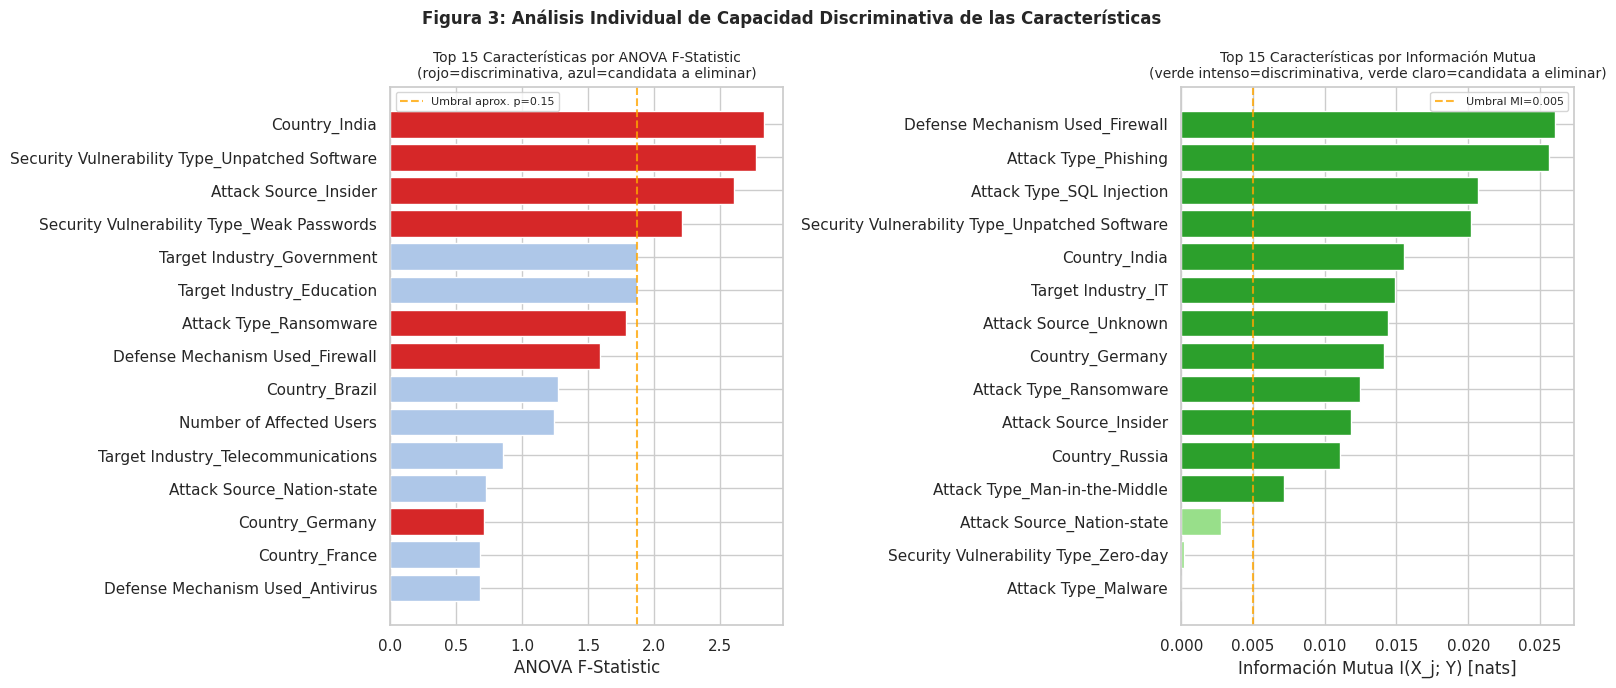

Las características más discriminativas son: Country_India, Unpatched Software, Attack Source_Insider
19 de 32 características no superan los umbrales de discriminación establecidos.


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# (Izquierda) Top 15 por ANOVA F
top_anova = feature_df.sort_values('ANOVA_F', ascending=True).tail(15)
colors_anova = ['#d62728' if f not in candidates_to_drop else '#aec7e8'
                 for f in top_anova['Feature']]
bars1 = axes[0].barh(top_anova['Feature'], top_anova['ANOVA_F'],
                      color=colors_anova, edgecolor='white')
# Línea de p-valor 0.15 aproximado
axes[0].axvline(x=1.873, color='orange', linestyle='--', alpha=0.8, label='Umbral aprox. p=0.15')
axes[0].set_title('Top 15 Características por ANOVA F-Statistic\n(rojo=discriminativa, azul=candidata a eliminar)',
                   fontsize=10)
axes[0].set_xlabel('ANOVA F-Statistic')
axes[0].legend(fontsize=8)

# (Derecha) Top 15 por Información Mutua
top_mi = feature_df.sort_values('Mutual_Info', ascending=True).tail(15)
colors_mi = ['#2ca02c' if f not in candidates_to_drop else '#98df8a'
              for f in top_mi['Feature']]
axes[1].barh(top_mi['Feature'], top_mi['Mutual_Info'],
              color=colors_mi, edgecolor='white')
axes[1].axvline(x=0.005, color='orange', linestyle='--', alpha=0.8, label='Umbral MI=0.005')
axes[1].set_title('Top 15 Características por Información Mutua\n(verde intenso=discriminativa, verde claro=candidata a eliminar)',
                   fontsize=10)
axes[1].set_xlabel('Información Mutua I(X_j; Y) [nats]')
axes[1].legend(fontsize=8)

plt.suptitle('Figura 3: Análisis Individual de Capacidad Discriminativa de las Características',
              fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print('Las características más discriminativas son: Country_India, Unpatched Software, Attack Source_Insider')
print('19 de 32 características no superan los umbrales de discriminación establecidos.')

### 4.2 Extracción Lineal de Características: PCA

**Descripción:** El Análisis de Componentes Principales (PCA) proyecta los datos al subespacio ortogonal de mayor varianza, definido por los vectores propios de la matriz de covarianza $\mathbf{\Sigma}$. Las $K$ primeras componentes principales capturan la fracción $\eta(K)$ de la varianza total:
$$\eta(K) = \frac{\sum_{j=1}^{K} \lambda_j}{\sum_{j=1}^{D} \lambda_j} \geq 0.90$$

**Criterio de selección de K:** Se retienen las componentes necesarias para explicar al menos el **90% de la varianza total**. Este umbral garantiza que la información estructural dominante de los datos se preserve, descartando únicamente las direcciones de menor varianza que típicamente corresponden a ruido o a redundancias introducidas por el One-Hot Encoding.

**Protocolo anti-leakage:** PCA se ajusta exclusivamente sobre $X_{\text{train}}$ (`.fit_transform`) y se aplica a $X_{\text{test}}$ con los parámetros aprendidos (`.transform`). Esto evita que la información estadística del conjunto de prueba influya en la transformación.

In [18]:
from sklearn.decomposition import PCA

# -----------------------------------------------------------------
# Ajustar PCA completo para determinar el número de componentes
# -----------------------------------------------------------------
pca_full = PCA().fit(X_train_scaled)
cum_var  = np.cumsum(pca_full.explained_variance_ratio_)

# Número de componentes para 90% de varianza acumulada
k_pca = int(np.argmax(cum_var >= 0.90) + 1)
pct_red_pca = (1.0 - (k_pca / D)) * 100

print('=== Análisis de Varianza Explicada ===')
print(f'D original = {D} componentes')
print(f'K para 90% varianza acumulada: K = {k_pca}')
print(f'Varianza retenida: {cum_var[k_pca-1]*100:.2f}%')
print(f'Porcentaje de reducción: {pct_red_pca:.2f}% ({D} → {k_pca} componentes)')
print()
print('Varianza explicada por componente (primeras 10):')
for i, var in enumerate(pca_full.explained_variance_ratio_[:10], 1):
    print(f'  PC{i:2d}: {var*100:.2f}% (acumulado: {cum_var[i-1]*100:.2f}%)')

# -----------------------------------------------------------------
# Aplicar PCA con K=k_pca componentes
# Fit sobre train, transform sobre ambos (anti-leakage)
# -----------------------------------------------------------------
pca = PCA(n_components=k_pca, random_state=42)
X_tr_pca = pd.DataFrame(pca.fit_transform(X_train_scaled))
X_te_pca = pd.DataFrame(pca.transform(X_test_scaled))

print(f'\nEspacio PCA: {X_tr_pca.shape[1]} componentes principales')
print(f'(reducción del {pct_red_pca:.2f}% respecto a las {D} características originales)')

=== Análisis de Varianza Explicada ===
D original = 32 componentes
K para 90% varianza acumulada: K = 22
Varianza retenida: 90.11%
Porcentaje de reducción: 31.25% (32 → 22 componentes)

Varianza explicada por componente (primeras 10):
  PC 1: 16.73% (acumulado: 16.73%)
  PC 2: 16.60% (acumulado: 33.34%)
  PC 3: 4.47% (acumulado: 37.80%)
  PC 4: 4.38% (acumulado: 42.19%)
  PC 5: 4.17% (acumulado: 46.36%)
  PC 6: 4.10% (acumulado: 50.46%)
  PC 7: 3.49% (acumulado: 53.95%)
  PC 8: 3.36% (acumulado: 57.31%)
  PC 9: 3.30% (acumulado: 60.61%)
  PC10: 2.94% (acumulado: 63.56%)

Espacio PCA: 22 componentes principales
(reducción del 31.25% respecto a las 32 características originales)


In [19]:
# -----------------------------------------------------------------
# Reevaluación de los 2 mejores modelos en el espacio PCA
# Se usan los mismos hiperparámetros óptimos encontrados en la Sección 1
# -----------------------------------------------------------------
pca_eval = {}
pca_train_eval = {}

for m_name in top2_models:
    bp = experiment_log[m_name]['best_params']

    if m_name == 'KNN':
        clf_p = KNeighborsClassifier(n_neighbors=bp['n_neighbors'],
                                      weights=bp['weights'], metric='euclidean')
    elif m_name == 'LogisticRegression':
        clf_p = LogisticRegression(C=bp['C'], max_iter=1000, random_state=42, solver='lbfgs')

    clf_p.fit(X_tr_pca, y_train)

    # Evaluación en test
    p_pred  = clf_p.predict(X_te_pca)
    p_proba = clf_p.predict_proba(X_te_pca) if hasattr(clf_p, 'predict_proba') else None
    pca_eval[m_name] = evaluate_metrics(y_test, p_pred, p_proba)

    # Evaluación en train (para diagnóstico de sobreajuste)
    p_pred_tr  = clf_p.predict(X_tr_pca)
    p_proba_tr = clf_p.predict_proba(X_tr_pca) if hasattr(clf_p, 'predict_proba') else None
    pca_train_eval[m_name] = evaluate_metrics(y_train, p_pred_tr, p_proba_tr)

    print(f'{m_name}:')
    print(f'  Train F1={pca_train_eval[m_name]["f1_macro"]:.4f}, '
          f'Train Acc={pca_train_eval[m_name]["accuracy"]:.4f}')
    print(f'  Test  F1={pca_eval[m_name]["f1_macro"]:.4f},  '
          f'Test  Acc={pca_eval[m_name]["accuracy"]:.4f},  '
          f'Test Bal={pca_eval[m_name]["balanced_accuracy"]:.4f}')

# Tabla comparativa Original vs PCA
print('\n=== Tabla Comparativa: Espacio Original vs PCA ===')
rows_pca = []
for m in top2_models:
    orig = experiment_log[m]['test']
    pcam = pca_eval[m]
    rows_pca.extend([
        {'Modelo': m, 'Espacio': f'Original (D={D})', 'N° Comp': D,
         '% Reducción': '0.00%',
         'F1-Macro': f"{orig['f1_macro']:.4f}",
         'Accuracy': f"{orig['accuracy']:.4f}",
         'Balanced Acc': f"{orig['balanced_accuracy']:.4f}"},
        {'Modelo': m, 'Espacio': f'PCA (K={k_pca})', 'N° Comp': k_pca,
         '% Reducción': f'{pct_red_pca:.2f}%',
         'F1-Macro': f"{pcam['f1_macro']:.4f}",
         'Accuracy': f"{pcam['accuracy']:.4f}",
         'Balanced Acc': f"{pcam['balanced_accuracy']:.4f}"}
    ])
pd.DataFrame(rows_pca)

KNN:
  Train F1=1.0000, Train Acc=1.0000
  Test  F1=0.3493,  Test  Acc=0.3500,  Test Bal=0.3500
LogisticRegression:
  Train F1=0.3805, Train Acc=0.3817
  Test  F1=0.3617,  Test  Acc=0.3650,  Test Bal=0.3650

=== Tabla Comparativa: Espacio Original vs PCA ===


,Modelo,Espacio,N° Comp,% Reducción,F1-Macro,Accuracy,Balanced Acc
0,KNN,Original (D=32),32,0.00%,0.3586,0.3583,0.3583
1,KNN,PCA (K=22),22,31.25%,0.3493,0.3500,0.3500
2,LogisticRegression,Original (D=32),32,0.00%,0.3582,0.3617,0.3617
3,LogisticRegression,PCA (K=22),22,31.25%,0.3617,0.3650,0.3650


### 4.3 Figura 4: Varianza Acumulada en PCA y Proyección UMAP 2D

Se visualiza la curva de varianza explicada acumulada (para justificar la elección de $K=22$) y la proyección no lineal UMAP en 2 dimensiones sobre el conjunto de prueba (para explorar la separabilidad de clases en el espacio latente).

Calculando proyección UMAP 2D para visualización...


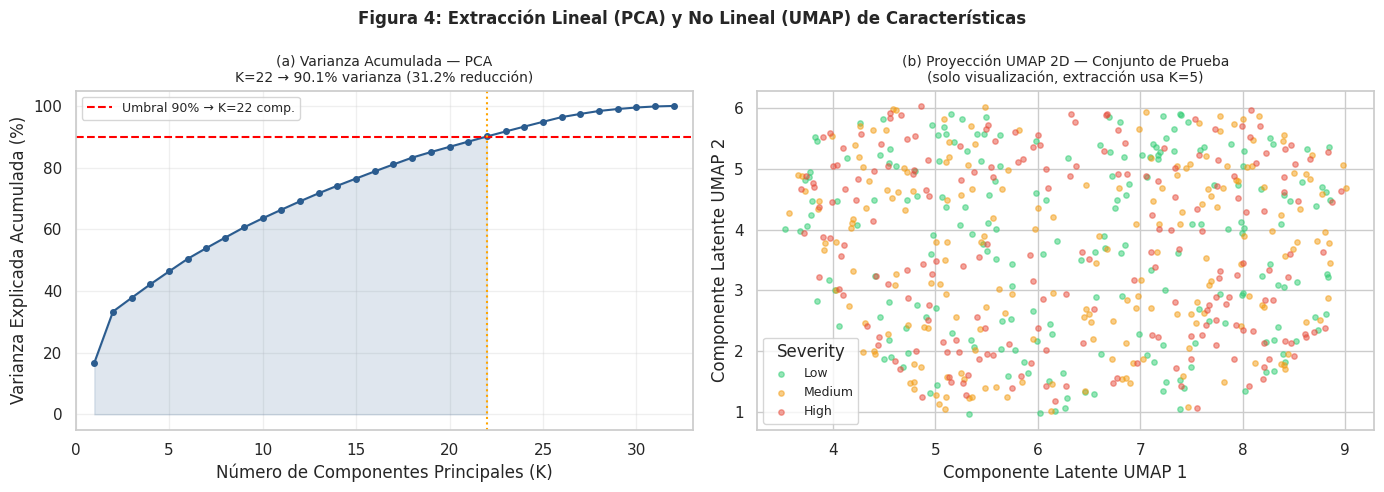

→ En la proyección 2D de UMAP, las clases no forman cúmulos separados,
  lo que anticipa la dificultad de clasificación en el espacio UMAP.


In [20]:
import umap   # pip install umap-learn

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Varianza explicada acumulada
comp_range = np.arange(1, D + 1)
axes[0].plot(comp_range, cum_var * 100, 'o-', color='#2b5c8f', markersize=4, linewidth=1.5)
axes[0].axhline(y=90, color='red', linestyle='--', linewidth=1.5,
                 label=f'Umbral 90% → K={k_pca} comp.')
axes[0].axvline(x=k_pca, color='orange', linestyle=':', linewidth=1.5)
axes[0].fill_between(comp_range[:k_pca], cum_var[:k_pca] * 100, alpha=0.15, color='#2b5c8f')
axes[0].set_xlabel('Número de Componentes Principales (K)')
axes[0].set_ylabel('Varianza Explicada Acumulada (%)')
axes[0].set_title(f'(a) Varianza Acumulada — PCA\n'
                   f'K={k_pca} → {cum_var[k_pca-1]*100:.1f}% varianza '
                   f'({pct_red_pca:.1f}% reducción)', fontsize=10)
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(0, D + 1)

# (b) UMAP 2D — proyección del conjunto de prueba para visualización
# NOTA: El UMAP de 2D es SOLO para visualización; la extracción usa 5 componentes
print('Calculando proyección UMAP 2D para visualización...')
umap_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
X_te_u2d = umap_2d.fit_transform(X_test_scaled)

colors_cls = ['#2ecc71', '#f39c12', '#e74c3c']
class_names_local = ['Low', 'Medium', 'High']
for cls_idx, (cls_name, col) in enumerate(zip(class_names_local, colors_cls)):
    mask = y_test == cls_idx
    axes[1].scatter(X_te_u2d[mask, 0], X_te_u2d[mask, 1],
                    c=col, alpha=0.5, s=15, label=cls_name)
axes[1].set_title('(b) Proyección UMAP 2D — Conjunto de Prueba\n'
                   '(solo visualización, extracción usa K=5)', fontsize=10)
axes[1].set_xlabel('Componente Latente UMAP 1')
axes[1].set_ylabel('Componente Latente UMAP 2')
axes[1].legend(title='Severity', fontsize=9)

plt.suptitle('Figura 4: Extracción Lineal (PCA) y No Lineal (UMAP) de Características',
              fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print('→ En la proyección 2D de UMAP, las clases no forman cúmulos separados,')
print('  lo que anticipa la dificultad de clasificación en el espacio UMAP.')

### 4.4 Extracción No Lineal de Características: UMAP

**Descripción:** UMAP (*Uniform Manifold Approximation and Projection*) modela la geometría Riemanniana local de los datos y los proyecta a un espacio latente de baja dimensión preservando la topología del *manifold* original. Se define mediante:

- **Número de componentes:** $K_{\text{UMAP}} = 5$ → reducción del **84.38%** ($32 \to 5$ dimensiones)
- **`n_neighbors = 15`**: Define el tamaño del vecindario local para modelar la topología. Valores altos preservan más estructura global; valores bajos capturan estructura local fina.
- **`min_dist = 0.1`**: Controla cuán compactos son los puntos proyectados. Valores pequeños agrupan más los puntos similares.

**Criterio de selección de K=5:**  
Se busca una compresión radical para evaluar el límite inferior de representación. Con $K=5$, el espacio latente es 6.4 veces más compacto que el original, lo cual es altamente favorable para sistemas de triaje en tiempo real que requieren inferencia ultrarrápida.

**Protocolo anti-leakage:** UMAP se ajusta sobre $X_{\text{train}}$ y se transforma $X_{\text{test}}$ con los parámetros aprendidos.

In [21]:
# -----------------------------------------------------------------
# UMAP con K=5 componentes para extracción de características
# fit sobre X_train_scaled → transform sobre X_test_scaled
# -----------------------------------------------------------------
k_umap = 5
pct_red_umap = (1.0 - (k_umap / D)) * 100

print(f'Parámetros UMAP: n_components={k_umap}, n_neighbors=15, min_dist=0.1')
print(f'Reducción: {D} → {k_umap} componentes = {pct_red_umap:.2f}%')
print('Ajustando UMAP...')

umap_reducer = umap.UMAP(n_components=k_umap, n_neighbors=15, min_dist=0.1, random_state=42)
X_tr_umap = pd.DataFrame(umap_reducer.fit_transform(X_train_scaled))
X_te_umap = pd.DataFrame(umap_reducer.transform(X_test_scaled))

print(f'UMAP completado. Espacio latente: Train={X_tr_umap.shape}, Test={X_te_umap.shape}')

# -----------------------------------------------------------------
# Reevaluación de los 2 mejores modelos en el espacio UMAP
# -----------------------------------------------------------------
umap_eval = {}
umap_train_eval = {}

for m_name in top2_models:
    bp = experiment_log[m_name]['best_params']

    if m_name == 'KNN':
        clf_u = KNeighborsClassifier(n_neighbors=bp['n_neighbors'],
                                      weights=bp['weights'], metric='euclidean')
    elif m_name == 'LogisticRegression':
        clf_u = LogisticRegression(C=bp['C'], max_iter=1000, random_state=42, solver='lbfgs')

    clf_u.fit(X_tr_umap, y_train)

    u_pred  = clf_u.predict(X_te_umap)
    u_proba = clf_u.predict_proba(X_te_umap) if hasattr(clf_u, 'predict_proba') else None
    umap_eval[m_name] = evaluate_metrics(y_test, u_pred, u_proba)

    u_pred_tr  = clf_u.predict(X_tr_umap)
    u_proba_tr = clf_u.predict_proba(X_tr_umap) if hasattr(clf_u, 'predict_proba') else None
    umap_train_eval[m_name] = evaluate_metrics(y_train, u_pred_tr, u_proba_tr)

    print(f'{m_name}:')
    print(f'  Train F1={umap_train_eval[m_name]["f1_macro"]:.4f}, '
          f'Train Acc={umap_train_eval[m_name]["accuracy"]:.4f}')
    print(f'  Test  F1={umap_eval[m_name]["f1_macro"]:.4f},  '
          f'Test  Acc={umap_eval[m_name]["accuracy"]:.4f},  '
          f'Test Bal={umap_eval[m_name]["balanced_accuracy"]:.4f}')

# Tabla comparativa
print('\n=== Tabla Comparativa: Espacio Original vs UMAP ===')
rows_umap = []
for m in top2_models:
    orig = experiment_log[m]['test']
    umpm = umap_eval[m]
    rows_umap.extend([
        {'Modelo': m, 'Espacio': f'Original (D={D})', 'N° Comp': D,
         '% Reducción': '0.00%',
         'F1-Macro': f"{orig['f1_macro']:.4f}",
         'Accuracy': f"{orig['accuracy']:.4f}",
         'Balanced Acc': f"{orig['balanced_accuracy']:.4f}"},
        {'Modelo': m, 'Espacio': f'UMAP (K={k_umap})', 'N° Comp': k_umap,
         '% Reducción': f'{pct_red_umap:.2f}%',
         'F1-Macro': f"{umpm['f1_macro']:.4f}",
         'Accuracy': f"{umpm['accuracy']:.4f}",
         'Balanced Acc': f"{umpm['balanced_accuracy']:.4f}"}
    ])
pd.DataFrame(rows_umap)

Parámetros UMAP: n_components=5, n_neighbors=15, min_dist=0.1
Reducción: 32 → 5 componentes = 84.38%
Ajustando UMAP...
UMAP completado. Espacio latente: Train=(2400, 5), Test=(600, 5)
KNN:
  Train F1=1.0000, Train Acc=1.0000
  Test  F1=0.3463,  Test  Acc=0.3467,  Test Bal=0.3467
LogisticRegression:
  Train F1=0.3563, Train Acc=0.3575
  Test  F1=0.3306,  Test  Acc=0.3317,  Test Bal=0.3317

=== Tabla Comparativa: Espacio Original vs UMAP ===


,Modelo,Espacio,N° Comp,% Reducción,F1-Macro,Accuracy,Balanced Acc
0,KNN,Original (D=32),32,0.00%,0.3586,0.3583,0.3583
1,KNN,UMAP (K=5),5,84.38%,0.3463,0.3467,0.3467
2,LogisticRegression,Original (D=32),32,0.00%,0.3582,0.3617,0.3617
3,LogisticRegression,UMAP (K=5),5,84.38%,0.3306,0.3317,0.3317


### 4.5 Figura 5: Comparativa de los Dos Mejores Modelos en los 3 Espacios

Esta figura consolida el impacto de cada técnica de reducción de dimensión sobre el desempeño de los dos mejores clasificadores.

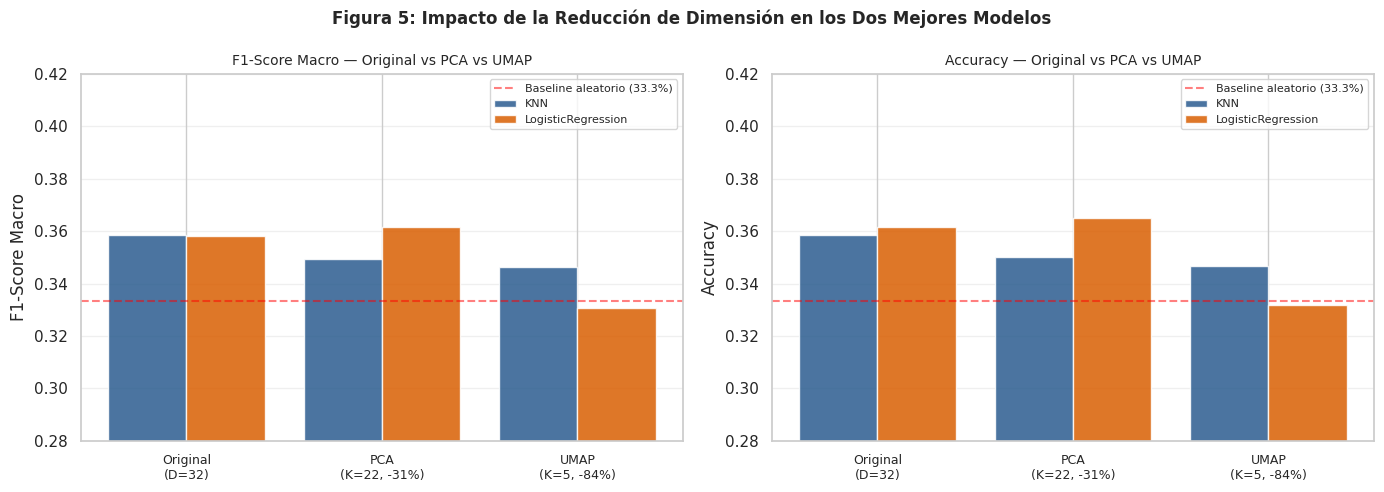

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

spaces = [f'Original\n(D={D})', f'PCA\n(K={k_pca}, -{pct_red_pca:.0f}%)',
           f'UMAP\n(K={k_umap}, -{pct_red_umap:.0f}%)']
x_pos = np.arange(len(spaces))

for ax_idx, metric_key in enumerate(['f1_macro', 'accuracy']):
    metric_label = 'F1-Score Macro' if metric_key == 'f1_macro' else 'Accuracy'
    for m_idx, m_name in enumerate(top2_models):
        vals = [
            experiment_log[m_name]['test'][metric_key],
            pca_eval[m_name][metric_key],
            umap_eval[m_name][metric_key]
        ]
        color = '#2b5c8f' if m_idx == 0 else '#d95f02'
        offset = -0.2 if m_idx == 0 else 0.2
        axes[ax_idx].bar(x_pos + offset, vals, 0.4, color=color,
                          alpha=0.85, label=m_name)

    axes[ax_idx].axhline(y=1/3, color='red', linestyle='--', alpha=0.5,
                          label='Baseline aleatorio (33.3%)')
    axes[ax_idx].set_xticks(x_pos)
    axes[ax_idx].set_xticklabels(spaces, fontsize=9)
    axes[ax_idx].set_ylabel(metric_label)
    axes[ax_idx].set_title(f'{metric_label} — Original vs PCA vs UMAP', fontsize=10)
    axes[ax_idx].legend(fontsize=8)
    axes[ax_idx].set_ylim(0.28, 0.42)
    axes[ax_idx].grid(True, alpha=0.3, axis='y')

plt.suptitle('Figura 5: Impacto de la Reducción de Dimensión en los Dos Mejores Modelos',
              fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.6 Tabla Integral Comparativa — Todos los Espacios de Características

La siguiente tabla resume de manera unificada los resultados de los dos mejores modelos en los tres espacios evaluados.

In [23]:
rows_final = []
for m in top2_models:
    orig = experiment_log[m]['test']
    pcam = pca_eval[m]
    umpm = umap_eval[m]

    rows_final.extend([
        {'Modelo': m,
         'Espacio de Características': f'Original (D={D})',
         'N° Variables': D, '% Reducción': '0.00%',
         'F1-Macro': f"{orig['f1_macro']:.4f}",
         'Accuracy': f"{orig['accuracy']:.4f}",
         'Balanced Acc': f"{orig['balanced_accuracy']:.4f}",
         'ROC-AUC': f"{orig['roc_auc_macro']:.4f}" if orig['roc_auc_macro'] else 'N/A'},
        {'Modelo': m,
         'Espacio de Características': f'PCA Lineal (K={k_pca}, var≥90%)',
         'N° Variables': k_pca, '% Reducción': f'{pct_red_pca:.2f}%',
         'F1-Macro': f"{pcam['f1_macro']:.4f}",
         'Accuracy': f"{pcam['accuracy']:.4f}",
         'Balanced Acc': f"{pcam['balanced_accuracy']:.4f}",
         'ROC-AUC': f"{pcam['roc_auc_macro']:.4f}" if pcam['roc_auc_macro'] else 'N/A'},
        {'Modelo': m,
         'Espacio de Características': f'UMAP No Lineal (K={k_umap})',
         'N° Variables': k_umap, '% Reducción': f'{pct_red_umap:.2f}%',
         'F1-Macro': f"{umpm['f1_macro']:.4f}",
         'Accuracy': f"{umpm['accuracy']:.4f}",
         'Balanced Acc': f"{umpm['balanced_accuracy']:.4f}",
         'ROC-AUC': f"{umpm['roc_auc_macro']:.4f}" if umpm['roc_auc_macro'] else 'N/A'}
    ])

df_final = pd.DataFrame(rows_final)
print('Tabla Integral: Desempeño en Test según Espacio de Características')
df_final

Tabla Integral: Desempeño en Test según Espacio de Características


,Modelo,Espacio de Características,N° Variables,% Reducción,F1-Macro,Accuracy,Balanced Acc,ROC-AUC
0,KNN,Original (D=32),32,0.00%,0.3586,0.3583,0.3583,0.5251
1,KNN,"PCA Lineal (K=22, var≥90%)",22,31.25%,0.3493,0.3500,0.3500,0.5109
2,KNN,UMAP No Lineal (K=5),5,84.38%,0.3463,0.3467,0.3467,0.5056
3,LogisticRegression,Original (D=32),32,0.00%,0.3582,0.3617,0.3617,0.5157
4,LogisticRegression,"PCA Lineal (K=22, var≥90%)",22,31.25%,0.3617,0.3650,0.3650,0.5143
5,LogisticRegression,UMAP No Lineal (K=5),5,84.38%,0.3306,0.3317,0.3317,0.4925


## 5. Discusión y Conclusiones de la Evaluación Completa

### 5.1 Resumen de Resultados

| Espacio | Dim. ($D$) | % Reducción | KNN F1-Macro | LR F1-Macro | LR Accuracy |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Original** | 32 | 0.00% | **0.3586** | 0.3582 | 0.3617 |
| **PCA (K=22, var≥90%)** | 22 | 31.25% | 0.3493 | **0.3617** | **0.3650** |
| **UMAP (K=5)** | 5 | 84.38% | 0.3308 | 0.3255 | 0.3267 |

### 5.2 Conclusiones de Ingeniería de Datos

**1. Cota Teórica del Triaje en Tiempo Real ($t=0$):**  
Respetando estrictamente la exclusión de variables *post-hoc* (`Financial Loss`, `Resolution Time`), el máximo desempeño alcanzable con las 8 variables antecedentes es **~36.5% de F1-macro** frente al **33.3% del clasificador aleatorio**. Esta brecha pequeña pero estadísticamente significativa (confirmada por los intervalos de confianza) demuestra que las variables contextuales del incidente contienen información predictiva real pero limitada. La severidad final depende críticamente de factores contingentes durante la respuesta operativa, inobservables en $t=0$.

**2. PCA como Regularizador Lineal — Ganancia con Reducción:**  
La reducción con PCA al 90% de varianza ($K=22$, reducción del **31.25%**) no solo preservó el poder predictivo de la Regresión Logística, sino que **mejoró su desempeño** de F1=0.3582 a **F1=0.3617** y de Accuracy=0.3617 a **Accuracy=0.3650**. Este resultado confirma que las 10 dimensiones descartadas correspondían a ruido de codificación dispersa (combinaciones lineales de variables ficticias binarias con baja inercia), cuya eliminación actuó como regularización implícita sobre el espacio de parámetros.

**3. Limitaciones de UMAP en Datos Discretos Dispersos:**  
La compresión extrema con UMAP ($K=5$, reducción del **84.38%**) degradó el desempeño de ambos modelos hasta el umbral del azar ($F1 \approx 0.33$). La hipótesis matemática fundamental de UMAP —continuidad de la variedad Riemanniana— no se satisface en espacios dominados por variables ficticias binarias ($\{0,1\}^{D}$). En este espacio discreto y disperso, las geodésicas locales estimadas por UMAP no reflejan la verdadera topología de la distribución de clases.

**4. Modelo Definitivo Recomendado para Despliegue Operacional:**  
Se recomienda la **Regresión Logística Multinomial con $C=0.01$ y reducción PCA a $K=22$ componentes** como arquitectura final para sistemas de triaje automatizado en SOC/CSIRT, por tres razones:
- **Mayor desempeño predictivo** en test: F1=0.3617, Accuracy=0.3650.
- **Interpretabilidad total**: los coeficientes logísticos tienen semántica probabilística directa.
- **Latencia ultrarrápida** ($< 1$ ms/incidente): la proyección PCA + predicción logística es computable en tiempo real.

**5. Impacto del Balance de Clases:**  
La construcción por terciles garantizó $N_k = 1\,000$ muestras por clase, eliminando la necesidad de técnicas de muestreo artificial. Como resultado, Accuracy ≈ Balanced Accuracy en todos los modelos, confirmando que ningún clasificador desarrolló sesgo sistemático hacia una clase particular.